<div align="center" dir="rtl">

<span style="color:#1F7A8C; font-weight:600; letter-spacing:0.5px;">درس پردازش زبان طبیعی</span>

# <span style="color:#1F7A8C;">Tokenization and N-gram LMs</span>


<span style="color:#5A6B7B;">دانشگاه تهران - دانشکده مهندسی برق و کامپیوتر</span>

<span style="color:#5A6B7B;">نیم‌سال اول ۰۵ - ۰۶ — مقطع کارشناسی ارشد</span>

<hr style="border:0; border-top:2px solid #1F7A8C; width:55%; margin:20px auto 24px auto;">

### <span style="color:#1F7A8C;">مشخصات تکلیف</span>

<div style="display:inline-block; text-align:right;">

| مورد | مقدار |
|---:|---:|
| شماره‌ی تکلیف | یک |
| مسئول تکلیف | علیرضا فرشی |
| ایمیل | azerila.farshi@gmail.com |
| تاریخ انتشار | ۲۸ / ۷ / ۱۴۰۵ |
| مهلت تحویل | ۱۰ / ۸ / ۱۴۰۵ |
| مهلت تحویل با تأخیر | ۱۷ / ۸ / ۱۴۰۵ |
| بارم کل | ۱۵۰ نمره |


</div>

### <span style="color:#1F7A8C;">مشخصات دانشجو</span>

<span style="color:#5A6B7B;">این جدول را پیش از ارسال تکمیل کنید.</span>

<div style="display:inline-block; text-align:right;">

| مورد | مقدار |
|---:|---:|
| نام و نام خانوادگی | سید نوید هاشمی |
| شماره‌ی دانشجویی |810105309|

</div>

<hr style="border:0; border-top:2px solid #1F7A8C; width:55%; margin:24px auto 8px auto;">

</div>

<div dir="rtl" align="right">

## مقدمه

در این تکلیف، دو موضوع بنیادی در پردازش زبان طبیعی بررسی می‌شود: **توکن‌سازی** و **مدل‌سازی زبانی با N-gram**. در بخش اول، الگوریتم **Byte Pair Encoding (BPE)** را از صفر پیاده‌سازی می‌کنیم؛ الگوریتمی که در مدل‌های زبانی مدرن مثل GPT-2 تا GPT-4 و Llama 3 استفاده می‌شود. هدف این بخش، درک عمیق نحوه‌ی تبدیل متن به توکن، ساخت واژگان زیرکلمه‌ای و مقایسه با پیاده‌سازی‌های حرفه‌ای است. در بخش دوم، مدل‌های زبانی **N-gram** را از مرتبه‌ی ۱ تا ۴ پیاده‌سازی کرده و تکنیک‌های هموارسازی (Smoothing) و Backoff را برای مقابله با مشکل پراکندگی داده ارزیابی می‌کنیم. در پایان، عملکرد مدل‌ها را با معیار Perplexity مقایسه و از بهترین مدل برای تولید متن استفاده خواهیم کرد.

### اهداف یادگیری

پس از انجام این تکلیف انتظار می‌رود بتوانید:

- الگوریتم BPE را از صفر پیاده‌سازی کرده و مراحل ساخت واژگان، آموزش و رمزگذاری/رمزگشایی را توضیح دهید.
- عملکرد توکنایزر خود را با پیاده‌سازی‌های آماده مثل `tiktoken` و Hugging Face مقایسه و بنچمارک کنید.
- مدل‌های زبانی N-gram را با روش MLE پیاده‌سازی کرده و معیار Perplexity را محاسبه کنید.
- تفاوت روش‌های هموارسازی (Laplace، Linear Interpolation، Stupid Backoff) را در کاهش perplexity تحلیل کنید.

</div>

<div dir="rtl" align="right">

## راهنمای انجام تکلیف

- **گام ۱.** سلول‌های بخش «۰. پیکربندی محیط» را پیش از هر کار دیگری اجرا کنید.
- **گام ۲.** سلول‌های کد دارای نشانه‌ی `WRITE YOUR CODE HERE` را تکمیل کنید. ترتیب و ساختار سلول‌ها را تغییر ندهید و سلولی را حذف نکنید. در صورت نیاز می‌توانید بلافاصله پس از سلول کد هر زیربخش، سلول کد تازه‌ای بیفزایید. کد خود را کامنت‌گذاری کنید و کامنت‌ها را به انگلیسی بنویسید.
- **گام ۳.** در سلول‌های «پاسخ تشریحی»، عبارت `{{پاسخ_خود_را_اینجا_بنویسید}}` را با پاسخ خود جایگزین کنید. پاسخ باید مختصر، مستدل و متکی بر خروجی کدی باشد که خودتان اجرا کرده‌اید.
- **گام ۴.** بخش «جمع‌بندی» و جدول «منابع و ابزارهای کمکی» را تکمیل کنید.
- **گام ۵.** نوت‌بوک را با `Restart & Run All` از ابتدا اجرا کنید و پیش از ذخیره مطمئن شوید خروجی همه‌ی سلول‌ها در فایل باقی مانده است.
- **گام ۶.** چک‌لیست انتهای نوت‌بوک را بررسی و سپس فایل را با نام `NLP_CA{n}_{LASTNAME}_{STUDENTID}.ipynb` ارسال کنید.

متن کامل قوانین در بخش پایانی نوت‌بوک، «قوانین تحویل و صداقت علمی»، آمده است.

</div>

---

<div dir="rtl" align="right">

## ۰. پیکربندی محیط

سلول‌های این بخش را بدون تغییر اجرا کنید. اگر برای پاسخ به سوال‌ها به کتابخانه‌ی دیگری نیاز داشتید، آن را به همین سلول‌ها اضافه کنید تا نوت‌بوک برای مصحح نیز قابل اجرا باشد.

</div>

In [ ]:
# Install the packages required by this assignment.
!pip install -q datasets tiktoken transformers matplotlib seaborn pandas numpy

In [ ]:
# Import libraries here.
import re
import math
import time
import timeit
import string
from collections import Counter, defaultdict

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import bpe_openai_gpt2
import urllib.request

# Hugging Face Datasets & Tokenizers for BPE and evaluation
from datasets import load_dataset
import tiktoken
from transformers import GPT2Tokenizer, GPT2TokenizerFast

# Configure plotting style
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

---

<div dir="rtl" align="right">

## ۱. پیاده‌سازی BPE Tokenizer از صفر

در این بخش، الگوریتم **Byte Pair Encoding (BPE)** را از صفر پیاده‌سازی می‌کنیم. ابتدا دادگان WikiText-2 را بارگذاری کرده و پیش‌پردازش می‌کنیم. سپس یک توکنایزر BPE کامل می‌سازیم که شامل مراحل ساخت واژگان، آموزش (یافتن و ادغام پرتکرارترین جفت‌ها)، رمزگذاری و رمزگشایی متن است. در ادامه، توکنایزر خود را روی داده‌ی test ارزیابی کرده و در نهایت عملکرد آن را با پیاده‌سازی‌های حرفه‌ای مثل `tiktoken` و توکنایزرهای Hugging Face از دو منظر کیفیت خروجی و سرعت اجرا بنچمارک می‌کنیم.

</div>

<div dir="rtl" align="right">

### ۱.۱ آشنایی و بارگذاری دادگان (۵ نمره)

**صورت مسئله**

در این تمرین از دادگان **WikiText-2** برای آموزش توکنایزر استفاده می‌کنیم. این دادگان مجموعه‌ای از مقالات ویکی‌پدیا است که متن آن‌ها تمیز شده و برای کارهای پردازش زبان طبیعی مناسب است. نسخه‌ی خام این دادگان ساختار اصلی متن (نشانه‌گذاری، حروف بزرگ و کوچک، فاصله‌ها) را حفظ می‌کند و به همین دلیل برای آموزش توکنایزر مناسب‌تر است.

**آنچه باید انجام دهید**

- دادگان WikiText-2 را بارگذاری کنید.
- محتوای دادگان را بررسی کنید و بخش train را به‌عنوان پیکره‌ی آموزشی در نظر بگیرید.
- یک نمونه از متن خام را چاپ کنید تا ساختار و ویژگی‌های آن مشخص شود.
- اندازه‌ی تقریبی پیکره (تعداد کاراکترها و خطوط) را گزارش کنید.
- درصد خطوط خالی یا خطوطی که فقط شامل نشانه‌گذاری هستند را محاسبه کنید.
- با نگاه به نمونه‌ی چاپ‌شده، حداقل دو ویژگی ساختاری متن (مثلاً وجود تگ‌های `<unk>`، خطوط عنوان ویکی‌پدیا، یا خطوط شروع‌شده با `=`) را نام ببرید و توضیح دهید هر کدام چه تأثیری روی توکن‌سازی BPE خواهند داشت.

</div>

In [ ]:
# Load the WikiText-2 dataset
wikitext_ds = load_dataset('Salesforce/wikitext', 'wikitext-2-raw-v1')
train_corpus = wikitext_ds['train']['text']

# Print a sample of the raw text
print("Samples(raw text): ")
for sample in range(0, 5):
  print(f"  train_corpus{sample}: ", train_corpus[sample])

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/validation-00000-of-00(…): reconstructing file:   0%|          |  0.00B /  657kB            

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Samples(raw text): 
  train_corpus0:  
  train_corpus1:   = Valkyria Chronicles III = 

  train_corpus2:  
  train_corpus3:   Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " . 

  train_corpus4:   The game began development in 2010 , carrying over a large portion of the work done on Valkyria Chronicles II . While it retained the standard featur

In [ ]:
# Report approximate size of the corpus
total_lines = len(train_corpus)
total_chars = 0
for line in train_corpus:
    total_chars += len(line)
print(f"Train Corpus Statistics: ")
print(f"  Total lines: {total_lines:,}")
print(f"  Total characters: {total_chars:,}")

Train Corpus Statistics: 
  Total lines: 36,718
  Total characters: 10,892,990


In [ ]:
# Count empty and punctuation-only lines in the corpus
empty_or_punct_count = 0
for line in train_corpus:
    line = line.strip()
    if line == "" or all(c in string.punctuation for c in line):
        empty_or_punct_count += 1

percentage = (empty_or_punct_count / len(train_corpus)) * 100

print("Empty or punctuation-only lines:", empty_or_punct_count)
print("Percentage:", round(percentage, 2), "%")

Empty or punctuation-only lines: 12951
Percentage: 35.27 %


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۱</b>
<br><br>
با توجه به خروجی چاپ شده، مشاهده می شود:

1- بعضی از خطوط، خالی هستند و هیچ محتوای مفیدی برای ادامه کار و توکن سازی ندارند و اگر پیش پردازش نشوند، احتمالا باعث می شوند توکن های بی معنی و غیرضروری ایجاد شوند.

2- بعضی از خطوط، با علامت = شروع شده و با همان علامت نیز تمام می شوند، این خطوط در واقع عناوین مقاله ها هستند. این موارد اگر زیاد تکرار شوند احتمالا در فرایند توکن سازی BPE، با کاراکتر های دیگر مرج خواهند شد.
</div>

<div dir="rtl" align="right">

### ۱.۲ پیش‌پردازش داده (۱۰ نمره)

**صورت مسئله**

متن خام WikiText-2، مثل هر پیکره‌ی متنی خام دیگری، ممکن است شامل ناهمگونی‌هایی مثل نوع‌های مختلف خط جدید، فاصله‌های تکراری، یا کاراکترهای اضافی باشد. اگر این ناهمگونی‌ها پیش از توکن‌سازی پاک نشوند، توکن‌های تکراری و بی‌معنا در واژگان ساخته می‌شوند و کیفیت مدل کاهش می‌یابد. بنابراین لازم است متن پیکره پیش از هر مرحله‌ی دیگری پاک‌سازی و نرمال‌سازی شود، به‌طوری که اطلاعات مفید متن (فاصله‌ها، خطوط جدید و نشانه‌گذاری) از بین نرود.

**آنچه باید انجام دهید**

- یک تابع با نام `preprocess` بنویسید که متن خام را دریافت کرده و نسخه‌ی پاک‌سازی‌شده و نرمال‌شده‌ی آن را برگرداند.
- هرگونه عملیات لازم برای پیش‌پردازش متن را **در همین تابع** پیاده‌سازی کنید.
- این تابع باید به‌گونه‌ای طراحی شود که خروجی‌اش ورودی مرحله‌ی بعدی (توکن‌سازی) باشد.
- تعداد کاراکترها و خطوط جدید را قبل و بعد از `preprocess` گزارش کنید.
- یک مثال مشخص بزنید: یک الگوی متنی (مثلاً فاصله‌ی تکراری یا خط جدید اضافی) که اگر پیش‌پردازش نمی‌کردید، باعث تولید یک توکن تکراری/بی‌معنا در واژگان BPE می‌شد.

</div>

In [ ]:
def preprocess(corpus):
    preprocessed_corpus = []
    for line in corpus:
        line = line.replace('\r', '')
        line = re.sub(r'[ \t]+', ' ', line)
        preprocessed_corpus.append(line)
    return preprocessed_corpus

In [ ]:
# Calculate stats before preprocessing
before_lines = len(train_corpus)
before_chars = sum(len(line) for line in train_corpus)

# Apply the preprocess function
processed_train_corpus = preprocess(train_corpus)

# Calculate stats after preprocessing
after_lines = len(processed_train_corpus)
after_chars = sum(len(line) for line in processed_train_corpus)

In [ ]:
# Report the results
print("Before Preprocessing:")
print(f"  Total lines: {before_lines:,}")
print(f"  Total characters: {before_chars:,}")

print("\nAfter Preprocessing:")
print(f"  Total lines: {after_lines:,}")
print(f"  Total characters: {after_chars:,}")

print(f"\nCharacter reduction: {before_chars - after_chars:,} characters")

Before Preprocessing:
  Total lines: 36,718
  Total characters: 10,892,990

After Preprocessing:
  Total lines: 36,718
  Total characters: 10,892,941

Character reduction: 49 characters


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۲</b>
<br><br>
فرض کنید در دادگان داشته باشیم "The -------------- game" بطوریکه - همان اسپیس باشد، اگر این اسپیس های اضافی را در مرحله پیش پردازش حذف نکنیم، ممکن است به دلیل تکرار، بعنوان یک توکن معنادار در نظر گرفته شوند و اینگونه بخشی از ظرفیت واژگان که قرار بود با توکن های معنادار پر شود جای خود را به این دست توکن های بی معنی می دهد.
</div>

<div dir="rtl" align="right">

### ۱.۳ پیاده‌سازی BPE (۲۵ نمره)

**صورت مسئله**

پیاده‌سازی الگوریتم BPE دو بخش اصلی دارد: نخست، ساختن واژگان اولیه بر پایه‌ی متن پیش‌پردازش‌شده که واحدهای پایه‌ی متن را در خود نگه می‌دارد و نگاشت معکوس آن را فراهم می‌کند. دوم، آموزش توکنایزر که طی آن متن به‌صورت مکرر بررسی شده، پرتکرارترین جفت توکن‌های مجاور پیدا و با یک توکن جدید جایگزین می‌شود. این فرآیند تا رسیدن به اندازه‌ی هدف واژگان یا اتمام جفت‌های قابل ادغام ادامه می‌یابد و اطلاعات هر ادغام برای مراحل بعدی نگه داشته می‌شود.

**آنچه باید انجام دهید**

- واژگان اولیه را بر پایه‌ی متن پیش‌پردازش‌شده بسازید و نگاشت معکوس آن را نیز فراهم کنید.
- قابلیت آموزش توکنایزر را پیاده‌سازی کنید که متن WikiText-2 و اندازه‌ی واژگان هدف را دریافت کرده و واژگان را به‌تدریج گسترش دهد.
- در هر گام، پرتکرارترین جفت توکن‌های مجاور را پیدا کرده و همه‌ی رخدادهای آن را با یک توکن جدید جایگزین کنید.
- فرآیند ادغام را تا رسیدن به اندازه‌ی هدف یا اتمام جفت‌های قابل ادغام ادامه دهید.
- اطلاعات مربوط به هر ادغام را نگه دارید تا در مراحل بعدی (رمزگذاری و رمزگشایی) قابل استفاده باشد.
- ۵ ادغام اول و ۵ ادغام آخر را چاپ کنید و الگوی تفاوت آن‌ها را تحلیل کنید (کاراکتری vs واژه‌ای).
- معیار tie-breaking خود را برای زمانی که چند جفت هم‌تکرار وجود دارد، مشخص کنید و توضیح دهید چرا ترتیب ادغام‌ها اهمیت دارد.
- زمان آموزش را برای دو اندازه‌ی واژگان هدف اندازه گیری و تحلیل کنید.

</div>

In [ ]:
class ScratchBPETokenizer:
    def __init__(self):
        self.vocab = set()
        self.merges = {}
        self.merge_order = []

    def train(self, corpus, target_vocab_size):
        start_time = time.time()

        # Initialize word frequencies with character tuples + '</w>'
        word_freqs = defaultdict(int)
        for text in corpus:
            for word in text.split():
                word_tuple = tuple(word) + ('</w>',)
                word_freqs[word_tuple] += 1

        # Build initial base vocabulary (all unique characters)
        self.vocab = set()
        for word_tuple in word_freqs.keys():
            for char in word_tuple:
                self.vocab.add(char)

        initial_vocab_size = len(self.vocab)
        print(f"Initial base vocabulary size (characters): {initial_vocab_size}")

        # Calculate how many merges we need
        num_merges = target_vocab_size - initial_vocab_size
        if num_merges < 0:
            print("Warning: Target vocab size is smaller than initial character set!")
            num_merges = 0

        # Iterative merging loop
        for i in range(num_merges):
            # Count frequencies of all adjacent symbol pairs
            pairs = defaultdict(int)
            for word_tuple, freq in word_freqs.items():
                for j in range(len(word_tuple) - 1):
                    pair = (word_tuple[j], word_tuple[j+1])
                    pairs[pair] += freq

            if not pairs:
                print("No more pairs to merge.")
                break

            # Find the most frequent pair.
            # Tie-breaking rule: pick max frequency, and lexicographically smallest pair if frequencies tie.
            best_pair = max(pairs.items(), key=lambda x: (x[1], x[0]))[0]
            new_token = best_pair[0] + best_pair[1]

            # Apply the merge across all word tuples in the corpus dictionary
            word_freqs = self._apply_merge(best_pair, new_token, word_freqs)

            # Record the merge rule
            self.merges[best_pair] = new_token
            self.merge_order.append(best_pair)
            self.vocab.add(new_token)

            if (i + 1) % 50 == 0 or i == 0 or i == num_merges - 1:
                print(f"  Merge {i+1}/{num_merges}: {best_pair} -> '{new_token}' (Freq: {pairs[best_pair]})")

        elapsed_time = time.time() - start_time
        print(f"\n  Training finished in {elapsed_time:.2f} seconds. Final Vocabulary Size: {len(self.vocab)}")
        return elapsed_time

    def _apply_merge(self, pair, new_token, word_freqs):
        p0, p1 = pair
        new_word_freqs = defaultdict(int)
        for word_tuple, freq in word_freqs.items():
            new_tuple = []
            i = 0
            while i < len(word_tuple):
                # If we find the pair, replace it with the new merged token
                if i < len(word_tuple) - 1 and word_tuple[i] == p0 and word_tuple[i+1] == p1:
                    new_tuple.append(new_token)
                    i += 2
                else:
                    new_tuple.append(word_tuple[i])
                    i += 1
            new_word_freqs[tuple(new_tuple)] += freq
        return new_word_freqs

In [ ]:
# Execution on the Full Training Corpus
print("Training BPE Tokenizer (Vocab size: 1200)")
bpe_tokenizer_1200 = ScratchBPETokenizer()
time_1200 = bpe_tokenizer_1200.train(processed_train_corpus, target_vocab_size=1200)

print("Training BPE Tokenizer (Vocab size: 1500)")
bpe_tokenizer_1500 = ScratchBPETokenizer()
time_1500 = bpe_tokenizer_1500.train(processed_train_corpus, target_vocab_size=1500)

# Print first 5 and last 5 merges from the larger vocab model
print("\nFirst 5 Merges (Vocab 1500):")
for idx, merge in enumerate(bpe_tokenizer_1500.merge_order[:5]):
    print(f"{idx + 1}. {merge} -> '{bpe_tokenizer_1500.merges[merge]}'")

print("\nLast 5 Merges (Vocab 1500):")
for idx, merge in enumerate(bpe_tokenizer_1500.merge_order[-5:]):
    print(f"{len(bpe_tokenizer_1500.merge_order) - 4 + idx}. {merge} -> '{bpe_tokenizer_1500.merges[merge]}'")

print(f"\nTime Comparison:")
print(f"  Time for Vocab 1200: {time_1200:.2f} seconds")
print(f"  Time for Vocab 1500: {time_1500:.2f} seconds")

Training BPE Tokenizer (Vocab size: 1200)
Initial base vocabulary size (characters): 1012
  Merge 1/188: ('e', '</w>') -> 'e</w>' (Freq: 315788)
  Merge 50/188: ('h', 'e</w>') -> 'he</w>' (Freq: 26497)
  Merge 100/188: ('en', 't') -> 'ent' (Freq: 12379)
  Merge 150/188: ('d', 's</w>') -> 'ds</w>' (Freq: 6989)
  Merge 188/188: ('al', 'l</w>') -> 'all</w>' (Freq: 5613)

  Training finished in 68.93 seconds. Final Vocabulary Size: 1200
Training BPE Tokenizer (Vocab size: 1500)
Initial base vocabulary size (characters): 1012
  Merge 1/488: ('e', '</w>') -> 'e</w>' (Freq: 315788)
  Merge 50/488: ('h', 'e</w>') -> 'he</w>' (Freq: 26497)
  Merge 100/488: ('en', 't') -> 'ent' (Freq: 12379)
  Merge 150/488: ('d', 's</w>') -> 'ds</w>' (Freq: 6989)
  Merge 200/488: ('4', '</w>') -> '4</w>' (Freq: 5244)
  Merge 250/488: ('t', 'w') -> 'tw' (Freq: 3906)
  Merge 300/488: ('m', 'ent</w>') -> 'ment</w>' (Freq: 3138)
  Merge 350/488: ('a', 'd</w>') -> 'ad</w>' (Freq: 2711)
  Merge 400/488: ('u', 'p</w>'

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۳</b>
<br><br>
همانطور که از خروجی ها مشخص است، merge های ابتدایی در سطح کاراکتر هستند و پرتکرارترین حروف انگلیسی کنار هم یا کنار نشانگر پایان کلمه را تشکیل می دهند، اما هر چه به merge های پایانی نزدیک می شویم، merge ها به سمت ساخت زیرواژه ها یا واژه های کامل (مثل old در خروجی vocabulary size:1500) حرکت کرده اند.

---

معیار tie-breaking که در کد قرار دادم بر اساس ترتیب الفبا تصمیم گیری میکند، همچنین اهمیت این ترتیب از این جهت است که اگر ما دو کاراکتر را زودتر از یکسری کاراکتر دیگر با هم merge کنیم، آنها را برای ساختترکیب های مهم تر و با معناتر از دست خواهیم داد و فرایند ساخت زیرواژه ها و در ادامه، ساخت خود واژگان تغییر خواهد کرد.

---

زمان آموزش برای اندازه واژگان 1200 تایی برابر 68.93 ثانیه و برای اندازه واژگان 1500 تایی برابر 166.93 ثانیه می باشد.
با اینکه اندازه واژگان 25% بیشتر شده اما زمان آموزش حدودا 142% بیشتر شده است.
دلیل این افزایش غیرخطی زمان آموزش، ماهیت این الگوریتم است، چراکه هر چه اندازه واژگان بیشتر می شود، تعداد merge هایی که باید انجام شود بیشتر می شود و ما در هر بار merge کردن باید کل متونمان را پیمایش کنیم تا هم دوباره یکسری آمار جمع کنیم و هم توکن جدید ساخته شده را با اجزای سازنده اش جایگزین کنیم.
</div>

<div dir="rtl" align="right">

### ۱.۴ رمزگذاری و رمزگشایی متن (۱۰ نمره)

**صورت مسئله**

پس از آموزش توکنایزر روی دادگان WikiText-2، باید بتوان یک متن جدید را به توکن تبدیل کرد (رمزگذاری) و سپس آن توکن‌ها را دوباره به متن اصلی بازگرداند (رمزگشایی). فرآیند رمزگذاری با اعمال ادغام‌هایی که در مرحله‌ی آموزش روی این دادگان یاد گرفته شده انجام می‌شود، و رمزگشایی با نگاشت معکوس توکن‌ها به رشته‌های متنی. خروجی رمزگشایی باید دقیقاً با متن ورودی یکسان باشد تا از حفظ اطلاعات اطمینان حاصل شود.

**آنچه باید انجام دهید**

- قابلیت رمزگذاری را پیاده‌سازی کنید که یک متن را به لیستی از توکن‌ها تبدیل کند.
- قابلیت رمزگشایی را پیاده‌سازی کنید که لیستی از توکن‌ها را به متن اصلی بازگرداند.
- این دو قابلیت را روی نمونه‌ای از متن دادگان WikiText-2 اجرا کنید و خروجی را گزارش دهید.

</div>

In [ ]:
def encode(self, text):
    final_tokens = []

    # Split text into words
    words = text.split()

    for word in words:
        # Convert word into characters and add end marker
        word_tokens = list(word)
        word_tokens.append('</w>')

        while True:
            best_priority = 999999
            best_pair = None

            # Check all adjacent pairs
            for i in range(len(word_tokens) - 1):
                pair = (word_tokens[i], word_tokens[i+1])

                # Check if the pair was merged during training
                if pair in self.merges:
                    # Lower index means higher merge priority
                    priority = self.merge_order.index(pair)

                    if priority < best_priority:
                        best_priority = priority
                        best_pair = pair

            # Stop if no mergeable pair remains
            if best_pair is None:
                break

            # Apply the highest-priority merge
            new_word_tokens = []
            i = 0

            while i < len(word_tokens):
                # Merge matching adjacent tokens
                if i < len(word_tokens) - 1 and (word_tokens[i], word_tokens[i+1]) == best_pair:
                    merged_token = self.merges[best_pair]
                    new_word_tokens.append(merged_token)
                    i += 2
                else:
                    new_word_tokens.append(word_tokens[i])
                    i += 1

            word_tokens = new_word_tokens

        # Add final word tokens to the output
        for token in word_tokens:
            final_tokens.append(token)

    return final_tokens

In [ ]:
def decode(self, tokens):
  text = ""
  # Concatenate all tokens
  for token in tokens:
    text = text + token
  # Replace end-of-word markers with spaces
  text = text.replace('</w>', ' ')
  # Remove leading and trailing whitespace
  return text.strip()

In [ ]:
# Attach methods to the existing class
ScratchBPETokenizer.encode = encode
ScratchBPETokenizer.decode = decode

In [ ]:
# Test on a sample from the training corpus
sample_text = processed_train_corpus[10]

print(f"Original Text:\n'{sample_text}'\n")

# Encode the text
encoded_tokens = bpe_tokenizer_1500.encode(sample_text)
print(f"Encoded Tokens:\n{encoded_tokens}\n")

# Decode the tokens
decoded_text = bpe_tokenizer_1500.decode(encoded_tokens)
print(f"Decoded Text:\n'{decoded_text}'\n")

# Verify exact reconstruction
is_match = (sample_text.strip() == decoded_text)
print(f"Exact Match Verification: {is_match}")

Original Text:
' The game 's battle system , the BliTZ system , is carried over directly from Valkyira Chronicles . During missions , players select each unit using a top @-@ down perspective of the battlefield map : once a character is selected , the player moves the character around the battlefield in third @-@ person . A character can only act once per @-@ turn , but characters can be granted multiple turns at the expense of other characters ' turns . Each character has a field and distance of movement limited by their Action Gauge . Up to nine characters can be assigned to a single mission . During gameplay , characters will call out if something happens to them , such as their health points ( HP ) getting low or being knocked out by enemy attacks . Each character has specific " Potentials " , skills unique to each character . They are divided into " Personal Potential " , which are innate skills that remain unaltered unless otherwise dictated by the story and can either help or im

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۴</b>
<br><br>

برای رمزگذاری، مانند کاری که در ساخت توکنایزر انجام دادیم،هر کلمه به حروف پایه‌ای شکسته شده و نشانگر آخر کلمات به انتهای آن متصل می‌شود. سپس الگوریتم روی توکن‌های هر کلمه پیمایش می‌کند و در هر مرحله، جفتی را برای ادغام انتخاب می‌کند که در لیست `merge_order` مرحله آموزش، کمترین اندیس (بیشترین اولویت زمانی) را داشته باشد. این حلقه تا جایی ادامه می‌یابد که دیگر هیچ جفت قابل ادغامی در کلمه یافت نشود.

---

برای decode کردن هم، توکن های encode شده در قالب یک رشته به یکدیگر متصل می‌شوند. سپس به عنوان نگاشت معکوس، نماد `</w>` که نشان‌دهنده مرز کلمات است، با کاراکتر اسپیس جایگزین می‌شود.

---

در خروجی سلول بالا مشاهده می شود که اجرای این دو تابع روی یک نمونه از داده موجود در دیتاست با موفقیت انجام شده و نتیجه بعد از decode دقیقا با قبل از encode یکسان است.


</div>

<div dir="rtl" align="right">

### ۱.۵ تست و ارزیابی توکنایزر (۱۰ نمره)

**صورت مسئله**

پس از پیاده‌سازی کامل توکنایزر و قابلیت‌های رمزگذاری و رمزگشایی، باید عملکرد آن در عمل ارزیابی شود. این ارزیابی دو جنبه دارد: نخست، بررسی رفتار توکنایزر روی **داده‌های دیده‌نشده** (بخش test دادگان WikiText-2) که در مرحله‌ی آموزش استفاده نشده است؛ دوم، بررسی رفتار آن روی یک **جمله‌ی دلخواه** که ممکن است الگوهای زبانی متفاوتی داشته باشد. هدف این است که اطمینان حاصل شود توکنایزر روی متن‌های جدید نیز به‌درستی کار می‌کند و قادر است متن اصلی را بدون افت اطلاعات بازسازی کند.

**آنچه باید انجام دهید**

- بخش test دادگان WikiText-2 را بارگذاری کنید.
- نمونه‌ای از متن بخش test را با توکنایزر آموزش‌دیده رمزگذاری کنید و سپس رمزگشایی کنید.
- درستی بازسازی متن (تطابق کامل رمزگشایی با متن اصلی) را تأیید کنید.
- تعداد کاراکترها را با تعداد توکن‌های تولیدشده مقایسه کرده و نسبت فشرده‌سازی را روی داده‌ی تست گزارش دهید.
- یک **جمله‌ی دلخواه** انتخاب کرده و همان مراحل رمزگذاری، رمزگشایی و بررسی درستی بازسازی را روی آن نیز اجرا کنید.
- گزارش کوتاهی از نحوه عملکرد توکنایزر پیاده سازی شده بدهید.

</div>

In [ ]:
# Load and preprocess the test dataset
test_corpus_raw = wikitext_ds['test']['text']
test_corpus = preprocess(test_corpus_raw)

# Remove empty lines
test_corpus = [line for line in test_corpus if line.strip() != ""]


# Test on an unseen sample
sample_test_text = test_corpus[5]

print("Test on WikiText-2 Test Sample")
print(f"  Original Text: '{sample_test_text}'")

encoded_test = bpe_tokenizer_1500.encode(sample_test_text)
decoded_test = bpe_tokenizer_1500.decode(encoded_test)

print(f"\n  Encoded Tokens ({len(encoded_test)} tokens):\n{encoded_test}")
print(f"\n  Decoded Text: '{decoded_test}'")
print(f"  Exact Match: {sample_test_text.strip() == decoded_test}")

Test on WikiText-2 Test Sample
  Original Text: ' In 2000 Boulter had a guest @-@ starring role on the television series The Bill ; he portrayed " Scott Parry " in the episode , " In Safe Hands " . Boulter starred as " Scott " in the play Herons written by Simon Stephens , which was performed in 2001 at the Royal Court Theatre . A review of Boulter 's performance in The Independent on Sunday described him as " horribly menacing " in the role , and he received critical reviews in The Herald , and Evening Standard . He appeared in the television series Judge John Deed in 2002 as " Addem Armitage " in the episode " Political Expediency " , and had a role as a different character " Toby Steele " on The Bill . 
'

  Encoded Tokens (293 tokens):
['In</w>', '200', '0</w>', 'B', 'ou', 'l', 'ter</w>', 'had</w>', 'a</w>', 'gu', 'est</w>', '@-@</w>', 'st', 'ar', 'r', 'ing</w>', 'ro', 'le</w>', 'on</w>', 'the</w>', 't', 'el', 'ev', 'is', 'ion</w>', 'ser', 'ies</w>', 'The</w>', 'B', 'il', 'l</w>', 

In [ ]:
# Calculate compression ratio on the full test dataset
total_chars = sum(len(line) for line in test_corpus)
total_tokens = 0

start_time = time.time()
for i, line in enumerate(test_corpus):
    tokens = bpe_tokenizer_1500.encode(line)
    total_tokens += len(tokens)

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(test_corpus)} lines...")

calc_time = time.time() - start_time
compression_ratio = total_chars / total_tokens

print(f"\nTotal Characters: {total_chars:,}")
print(f"Total Tokens generated: {total_tokens:,}")
print(f"Compression Ratio: {compression_ratio:.2f} (Average characters per token)")
print(f"Calculation took {calc_time:.2f} seconds.")

Processed 500/2891 lines...
Processed 1000/2891 lines...
Processed 1500/2891 lines...
Processed 2000/2891 lines...
Processed 2500/2891 lines...

Total Characters: 1,285,618
Total Tokens generated: 549,846
Compression Ratio: 2.34 (Average characters per token)
Calculation took 11.25 seconds.


In [ ]:
# Test on a custom sentence with different patterns and new words
custom_sentence = "Hello! My name is Navid, and I'm a huge fan of Barcelona football club."

print(f"Original Text: '{custom_sentence}'")

encoded_custom = bpe_tokenizer_1500.encode(custom_sentence)
decoded_custom = bpe_tokenizer_1500.decode(encoded_custom)

print(f"\nEncoded Tokens:\n{encoded_custom}")
print(f"\nDecoded Text: '{decoded_custom}'")
print(f"Exact Match: {custom_sentence.strip() == decoded_custom}")

Original Text: 'Hello! My name is Navid, and I'm a huge fan of Barcelona football club.'

Encoded Tokens:
['H', 'ell', 'o', '!', '</w>', 'M', 'y</w>', 'n', 'ame</w>', 'is</w>', 'N', 'a', 'vi', 'd', ',</w>', 'and</w>', 'I', "'", 'm</w>', 'a</w>', 'h', 'u', 'ge</w>', 'f', 'an</w>', 'of</w>', 'B', 'ar', 'c', 'el', 'on', 'a</w>', 'f', 'oo', 't', 'b', 'all</w>', 'clu', 'b', '.</w>']

Decoded Text: 'Hello! My name is Navid, and I'm a huge fan of Barcelona football club.'
Exact Match: True


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۵</b>
<br><br>

رفتار روی داده‌های دیده‌نشده توکنایزر با موفقیت توانست متون بخش تست را که در مرحله‌ی آموزش ندیده بود، به توکن‌های زیرکلمه (مانند نمونه‌ی ۲۹۳ توکنی) رمزگذاری و سپس دقیقاً بازسازی کند.

 همانطور که مشاهده می شود هیچ کلمه‌ای به عنوان «ناشناخته» دور ریخته نشد؛ کلماتی که در واژگان نبودند به‌درستی تا سطح کاراکترهای پایه‌ی خود شکسته شدند.(مانند اسم خودم Navid که به N,a,vi,d شکسته شد.)

---

**نسبت فشرده‌سازی :** بر اساس اجرای توکنایزر روی کل داده‌های تست (پیمایش بیش از ۱.۲۸ میلیون کاراکتر)، نسبت فشرده‌سازی **۲.۳۴** به دست آمد. این یعنی هر توکن تولیدشده به طور میانگین، بارِ ۲.۳۴ کاراکتر را به دوش می‌کشد، که نشان‌دهنده عملکرد مطلوب الگوریتم در شناسایی پیشوندها، پسوندها و ریشه‌های پرتکرار با وجود اندازه‌ی واژگان محدود (۱۵۰۰) است.

---

**بررسی روی جمله‌ی دلخواه:** جمله‌ی انتخابی حاوی کلماتی بود که در دادگان آموزشی وجود نداشتند (مانند اسامی خاصی مانند اسم خودم و بارسلونا). توکنایزر بدون بروز خطا، این کلمات جدید را با استفاده از توکن‌های کوچکتر و حروف پایه رمزگذاری کرد
.

<div dir="rtl" align="right">

### ۱.۶ بنچمارک و مقایسه با پیاده‌سازی‌های آماده (۱۵ نمره)

**صورت مسئله**

توکنایزر BPE پیاده‌سازی‌شده در این تمرین برای اهداف آموزشی طراحی شده و اولویت آن خوانایی کد است، نه کارایی. در این زیربخش، پیاده‌سازی خودتان را با سه توکنایزر آماده از دو منظر **کیفیت خروجی** و **سرعت اجرا** مقایسه می‌کنید.

**توکنایزرهای مقایسه:**

- `tiktoken` (توکنایزر رسمی OpenAI برای GPT-2)
- پیاده‌سازی اصلی GPT-2 (فایل آن در اختیار شما قرار داده  شده است)
- توکنایزر Hugging Face (`GPT2Tokenizer` و نسخه‌ی سریع `GPT2TokenizerFast`)

**آنچه باید انجام دهید**

- خروجی رمزگذاری هر چهار توکنایزر را روی یک متن نمونه مقایسه کنید.
- زمان رمزگذاری را روی یک پیکره‌ی ثابت با `%timeit` اندازه‌گیری کنید.
- نتایج را در قالب جدول (میانگین زمان، انحراف معیار، نسبت سرعت) گزارش دهید.
- تحلیل کنید چرا پیاده‌سازی‌های حرفه‌ای سریع‌تر هستند و آیا خروجی توکنایزر شما با آن‌ها یکسان است.

</div>

In [ ]:
# Hugging Face GPT2
hf_tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
hf_tokenizer_fast = GPT2TokenizerFast.from_pretrained("gpt2")

# OpenAI Tiktoken
tiktoken_enc = tiktoken.get_encoding("gpt2")

# Original GPT-2
print("Downloading GPT-2 vocab for original implementation")
bpe_openai_gpt2.download_vocab()
original_gpt2_enc = bpe_openai_gpt2.get_encoder("gpt2_model", ".")


# Compare Outputs on a Sample Text
sample_text = "Spain was the champion of the 2026 worldcup this year.."
print(f"\n--- Output Comparison ---\nOriginal Text: '{sample_text}'")

# My BPE Tokenizer
custom_tokens = bpe_tokenizer_1500.encode(sample_text)
print(f"\n1. Custom BPE (1500 Vocab):\nTokens: {custom_tokens}\nLength: {len(custom_tokens)}")

# Hugging Face Fast
hf_tokens = hf_tokenizer_fast.encode(sample_text)
hf_decoded = [hf_tokenizer_fast.decode([t]) for t in hf_tokens]
print(f"\n2. HF GPT2TokenizerFast:\nTokens: {hf_decoded}\nLength: {len(hf_tokens)}")

# Tiktoken
tik_tokens = tiktoken_enc.encode(sample_text)
tik_decoded = [tiktoken_enc.decode([t]) for t in tik_tokens]
print(f"\n3. tiktoken:\nTokens: {tik_decoded}\nLength: {len(tik_tokens)}")

# Original GPT-2
orig_tokens = original_gpt2_enc.encode(sample_text)
orig_decoded = [original_gpt2_enc.decode([t]) for t in orig_tokens]
print(f"\n4. Original GPT-2:\nTokens: {orig_decoded}\nLength: {len(orig_tokens)}")

# Benchmarking Execution Speed
print("\nBenchmarking Speed (100 iterations)")
bench_text = " ".join(processed_train_corpus[:10])

def run_custom(): bpe_tokenizer_1500.encode(bench_text)
def run_hf_fast(): hf_tokenizer_fast.encode(bench_text)
def run_tiktoken(): tiktoken_enc.encode(bench_text)
def run_orig(): original_gpt2_enc.encode(bench_text)

# Run timeit
times_custom = timeit.repeat(run_custom, number=1, repeat=10)
times_hf = timeit.repeat(run_hf_fast, number=1, repeat=10)
times_tik = timeit.repeat(run_tiktoken, number=1, repeat=10)
times_orig = timeit.repeat(run_orig, number=1, repeat=10)

Fetching encoder.json: 1.04Mit [00:00, 2.59Mit/s]                                                   
Fetching vocab.bpe: 457kit [00:00, 1.52Mit/s]                                                       



--- Output Comparison ---
Original Text: 'Spain was the champion of the 2026 worldcup this year..'

1. Custom BPE (1500 Vocab):
Tokens: ['S', 'p', 'ain</w>', 'was</w>', 'the</w>', 'ch', 'am', 'p', 'ion</w>', 'of</w>', 'the</w>', '20', '2', '6</w>', 'wor', 'l', 'd', 'c', 'up</w>', 'this</w>', 'y', 'ear', '.', '.</w>']
Length: 24

2. HF GPT2TokenizerFast:
Tokens: ['Spain', ' was', ' the', ' champion', ' of', ' the', ' 20', '26', ' world', 'cup', ' this', ' year', '..']
Length: 13

3. tiktoken:
Tokens: ['Spain', ' was', ' the', ' champion', ' of', ' the', ' 20', '26', ' world', 'cup', ' this', ' year', '..']
Length: 13

4. Original GPT-2:
Tokens: ['Spain', ' was', ' the', ' champion', ' of', ' the', ' 20', '26', ' world', 'cup', ' this', ' year', '..']
Length: 13

Benchmarking Speed (100 iterations)


In [ ]:
#Results Table
results = pd.DataFrame({
    'Tokenizer': ['Custom BPE (Pure Python)', 'Original GPT-2 (Python)', 'HF GPT2Fast (Rust)', 'Tiktoken (Rust)'],
    'Mean Time (s)': [np.mean(times_custom), np.mean(times_orig), np.mean(times_hf), np.mean(times_tik)],
    'Std Dev (s)': [np.std(times_custom), np.std(times_orig), np.std(times_hf), np.std(times_tik)]
})

# Calculate speed ratio relative to the fastest (Tiktoken)
baseline = results['Mean Time (s)'].min()
results['Speed Ratio'] = results['Mean Time (s)'] / baseline

print("\n")
print(results.to_markdown(index=False))



| Tokenizer                |   Mean Time (s) |   Std Dev (s) |   Speed Ratio |
|:-------------------------|----------------:|--------------:|--------------:|
| Custom BPE (Pure Python) |     0.0226592   |   0.000525215 |      89.0698  |
| Original GPT-2 (Python)  |     0.00236038  |   0.00244115  |       9.27826 |
| HF GPT2Fast (Rust)       |     0.0020125   |   0.000940942 |       7.91081 |
| Tiktoken (Rust)          |     0.000254399 |   6.10876e-05 |       1       |


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۱.۶</b>
<br><br>
در خروجی دو سلول بالاتر مشخص است که خروجی توکنایرزی که ما پیاده سازی کردیم، با خروجی توکنایزر های مرجع یکسان نیست. توکنایزر ما، نمونه را به 24 توکن تقسیم میکند اما توکنایزر های مرجع،آن را به 13 توکن بهینه تر تقسیم میکنند. علت اصلی این است که vocabulary size توکنایزر ما در مقابل این توکنایزر ها، بسیار اندازه کوچک تری دارد و خب به تبع آن، بیشتر از زیرواژگان و کاراکتر ها تشکیل شده است. توکنایزر های مرحع معمولا اندازه واژگانی در اردر 50,000 دارند. علاوه بر آن، این توکنایزر های حرفه ای تر، از تکنیکی با عنوان Byte-level BPE استفاده می کنند که روش متفاوتی را در برخورد با کارکتر ها در پیش می گیرد.

---

<b>جدول نتایج بنچمارک:</b>
<table style="width:100%; border-collapse: collapse; margin-top: 10px; margin-bottom: 20px; text-align: right;">
  <tr style="border-bottom: 2px solid #D9A441; color: #8A6116;">
    <th style="padding: 8px;">توکنایزر</th>
    <th style="padding: 8px;">میانگین زمان (ثانیه)</th>
    <th style="padding: 8px;">انحراف معیار (ثانیه)</th>
    <th style="padding: 8px;">نسبت سرعت</th>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px;">MY BPE </td>
    <td style="padding: 8px; direction: ltr;">0.02265</td>
    <td style="padding: 8px; direction: ltr;">0.00052</td>
    <td style="padding: 8px; direction: ltr;">89.06</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px;">Original GPT-2 (پایتون)</td>
    <td style="padding: 8px; direction: ltr;">0.00236</td>
    <td style="padding: 8px; direction: ltr;">0.00244</td>
    <td style="padding: 8px; direction: ltr;">9.27</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px;">HF GPT2Fast (Rust)</td>
    <td style="padding: 8px; direction: ltr;">0.00201</td>
    <td style="padding: 8px; direction: ltr;">0.00094</td>
    <td style="padding: 8px; direction: ltr;">7.91</td>
  </tr>
  <tr style="border-bottom: 2px solid #D9A441;">
    <td style="padding: 8px; font-weight: bold;">Tiktoken (Rust)</td>
    <td style="padding: 8px; direction: ltr; font-weight: bold;">0.00025</td>
    <td style="padding: 8px; direction: ltr; font-weight: bold;">0.00006</td>
    <td style="padding: 8px; direction: ltr; font-weight: bold;">1.00</td>
  </tr>
</table>

---

با توجه به جدول مشخص است که سریعترین عملکرد مربوط به tiktoken است و توکنایزر ما حدودا 89 برابر کندتر از آن می باشد. اما این سرعت زیاد tiktoken دلایل مختلفی دارد، اول اینکه کتابخانه های tiktoken و GPT2Tokenizer در هسته خود با زبان برنامه نویسی Rust نوشته شده اند که به مراتب سریعتر از پایتون اجرا می شوند، دوما اینکه این توکنایزر ها قبل از استفاده از BPE، متن را با استفاده از Regex به الگو های قاعده مند تبدیل می کنند و این کمک میکند فرایند merge کردن با سرعت بیشتری انجام شود،همچنین بغضی از این توکنایزر های حرفه ای ، از caching در فرایند خودشان استفاده می کنند، در واقع کلماتی را که یکبار تجزیه کرده اند در cacheنگه می دارند تا در برخورد های بعدی، محاسبات اضافی انجام نشود.
</div>

<div dir="rtl" align="right">

## ۲. مدل‌سازی زبانی با N-gram

در این بخش، مدل‌های زبانی N-gram را پیاده‌سازی و ارزیابی می‌کنیم. هدف، درک trade-off بین مرتبه‌های مختلف N-gram و نقش حیاتی تکنیک‌های هموارسازی و backoff در مقابله با مشکل پراکندگی داده (data sparsity) است. ابتدا مدل‌های MLE با N=1 تا N=4 را می‌سازیم، سپس سه روش هموارسازی (Laplace، Linear Interpolation و Backoff) را پیاده‌سازی کرده و عملکرد آن‌ها را با معیار Perplexity روی داده‌ی test مقایسه می‌کنیم. در پایان، از بهترین مدل برای تولید متن استفاده خواهیم کرد.

</div>

<div dir="rtl" align="right">

### ۲.۱ بارگذاری و پیش‌پردازش دادگان (۱۰ نمره)

**صورت مسئله**

در این بخش از دادگان **Penn Treebank** برای آموزش مدل‌های زبانی N-gram استفاده می‌کنیم. این دادگان شامل سه بخش train، validation و test است. متن هر خط یک جمله است و باید پیش از آموزش، توکنایز شده و توکن‌های مرزی ابتدا و انتهای جمله به آن اضافه شوند. همچنین باید واژگان از داده‌ی train ساخته شود و کلمات خارج از واژگان با `<unk>` جایگزین شوند.

**آنچه باید انجام دهید**

- سه فایل `ptb.train.txt`، `ptb.valid.txt` و `ptb.test.txt` را بارگذاری کنید.
- هر جمله را توکنایز کرده و توکن‌های مرزی `<s>` و `</s>` را به ابتدا و انتهای آن اضافه کنید. (برای توکنایز کردن امکان استفاده از کتابخانه های آماده می باشد)
- واژگان را از داده‌ی train بسازید و در صورت نیاز از `<unk>` برای کلمات نادر استفاده کنید.
- تعداد جملات هر بخش و اندازه‌ی واژگان را گزارش دهید.
- توضیح دهید اگر توکن‌های `<s>` و `</s>` را اضافه نمی‌کردیم، محاسبه‌ی احتمال جمله چگونه تحت تأثیر قرار می‌گرفت.

</div>

In [ ]:
# ==============================================================
# Part 2.1 — Loading and Preprocessing the Penn Treebank Dataset
# ==============================================================
urls = {
    'ptb.train.txt': 'https://raw.githubusercontent.com/wojzaremba/lstm/master/data/ptb.train.txt',
    'ptb.valid.txt': 'https://raw.githubusercontent.com/wojzaremba/lstm/master/data/ptb.valid.txt',
    'ptb.test.txt': 'https://raw.githubusercontent.com/wojzaremba/lstm/master/data/ptb.test.txt'
}

# Download files
for filename, url in urls.items():
    urllib.request.urlretrieve(url, filename)

# Define the tokenizer and add boundary tokens
def load_and_tokenize(filename):
    sentences = []
    with open(filename, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                # Split by spaces and add boundary tokens
                tokens = ['<s>'] + line.split() + ['</s>']
                sentences.append(tokens)
    return sentences

# Load all three dataset splits
train_data = load_and_tokenize('ptb.train.txt')
valid_data = load_and_tokenize('ptb.valid.txt')
test_data = load_and_tokenize('ptb.test.txt')


# Build the vocabulary from the training data
word_counts = Counter()
for sentence in train_data:
    word_counts.update(sentence)

# Include words that appear at least once in training data
# PTB already replaces rare words with <unk>
vocab = set(word for word, count in word_counts.items() if count >= 1)
vocab.add('<unk>')

# Replace out-of-vocabulary (OOV) words with <unk>
def replace_oov(data, vocabulary):
    processed_data = []
    for sentence in data:
        processed_sentence = [
            word if word in vocabulary else '<unk>' for word in sentence
        ]
        processed_data.append(processed_sentence)
    return processed_data

train_data = replace_oov(train_data, vocab)
valid_data = replace_oov(valid_data, vocab)
test_data = replace_oov(test_data, vocab)

In [ ]:
# Dataset statistics
print(f"--- Dataset Statistics ---")
print(f"Train sentences: {len(train_data):,}")
print(f"Valid sentences: {len(valid_data):,}")
print(f"Test sentences:  {len(test_data):,}")
print(f"Vocabulary Size: {len(vocab):,}")


# Print a sample sentence
print("\nSample processed sentence (Train):")
print(train_data[2])

--- Dataset Statistics ---
Train sentences: 42,068
Valid sentences: 3,370
Test sentences:  3,761
Vocabulary Size: 10,001

Sample processed sentence (Train):
['<s>', 'mr.', '<unk>', 'is', 'chairman', 'of', '<unk>', 'n.v.', 'the', 'dutch', 'publishing', 'group', '</s>']


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۱</b>
<br><br>

آمار دیتاست به شرح زیر است:
<table style="width: 100%; border-collapse: collapse; font-family: Arial, sans-serif; text-align: center;">
  <thead>
    <tr style="background-color: #2F5597; color: white;">
      <th style="padding: 12px; border: 1px solid #ddd;">Dataset Statistic</th>
      <th style="padding: 12px; border: 1px solid #ddd;">Value</th>
    </tr>
  </thead>
  <tbody>
    <tr style="background-color: #f2f2f2;">
      <td style="padding: 10px; border: 1px solid #ddd;">Training Sentences</td>
      <td style="padding: 10px; border: 1px solid #ddd;">42,068</td>
    </tr>
    <tr>
      <td style="padding: 10px; border: 1px solid #ddd;">Validation Sentences</td>
      <td style="padding: 10px; border: 1px solid #ddd;">3,370</td>
    </tr>
    <tr style="background-color: #f2f2f2;">
      <td style="padding: 10px; border: 1px solid #ddd;">Test Sentences</td>
      <td style="padding: 10px; border: 1px solid #ddd;">3,761</td>
    </tr>
    <tr>
      <td style="padding: 10px; border: 1px solid #ddd;">Vocabulary Size</td>
      <td style="padding: 10px; border: 1px solid #ddd;">10,001</td>
    </tr>
  </tbody>
</table>

---

اگر توکن های مرزی شروع و پایان جمله را اضافه نکنیم، مدل در محاسبه احتمال کلماتی که جملات را شروع می کنند و همچنین کلماتی که معمولا پایان جملات را تشکیل می دهند دچار مشکل خواهد شود.

در این مدل، احتمال وقوعل هر کلمه ای بر اساس کلمات قبلی اش است، کلمه شروع کننده جمله، کلمه قبلی ندارد پس ما باید با یک سازوکار به مدل یاد بدهیم که چه کلماتی بیشترین احتمال را برای شروع جمله دارند، به همین دلیل توکن مرزی را به ابتدای جملات قرار می دهیم تا مدل بتواند احتمال رخداد کلمه اوب جمله را با دانشی که از توکن مرزی قبلی اش دارد یاد بگیرد.

در انتهای جملات هم مورد مشابهی وجود دارد. بدون توکن مرزی انتهایی، اگر این توکن را نداشته باشیم، رویداد به پایان رسیدن جمله مدلسازی نمی شود. پس مدل نمیداند که چه کلماتی نقطه پایانی جملات هستند پس هنگام تولید متن، هیچگاه متوقف نمی شود و جملات بدون پایان خواهند بود.همچنین از نظر ریاضیاتی و احتمالاتی، توزیع احتمالی که مدل یادمیگیرد باید مجموع احتمالات تمام جملات ممکن با طول متغیر برابر 1 شود و در غیاب استفاده از این توکن های ابتدایی و انتهایی جملات، مدل ناقص خواهد بود و مجموع احتمالات فضاهای نمونه کمتر از 1 خواهد شد.
</div>

<div dir="rtl" align="right">

### ۲.۲ پیاده‌سازی مدل N-gram (۲۰ نمره)

**صورت مسئله**

مدل زبانی N-gram احتمال یک توکن را بر اساس N-1 توکن قبلی تخمین می‌زند. در روش Maximum Likelihood Estimation (MLE)، این احتمال از نسبت شمارش N-gram به شمارش کانتکست به‌دست می‌آید. برای ارزیابی مدل، از معیار **Perplexity** استفاده می‌کنیم که معکوس احتمال نرمال‌شده‌ی مجموعه‌ی test است.

**آنچه باید انجام دهید**

- یک مدل زبانی N-gram پیاده‌سازی کنید که از هر مقدار N پشتیبانی کند.
- احتمال هر N-gram را با روش MLE محاسبه کنید.
- تابع محاسبه‌ی log-probability یک جمله و perplexity روی یک مجموعه را پیاده کنید.
- در محاسبات، کلمات خارج از واژگان را با `<unk>` جایگزین کنید.
- توضیح دهید در MLE اگر یک n-gram در train دیده نشده باشد، perplexity کل مجموعه چه می‌شود و در کد شما این حالت چگونه مدیریت شده است

</div>

In [ ]:
# ==============================================================
# Part 2.2 — N-gram Model Implementation (MLE)
# ==============================================================
class NGramModel:
    def __init__(self, n, vocab):
        """
        Initializes the N-gram language model.
        n: order of the n-gram
        vocab: set of known words in the vocabulary
        """
        self.n = n
        self.vocab = vocab
        self.ngram_counts = Counter()
        self.context_counts = Counter()

    def _replace_unk(self, sentence):
        """
        Replaces Out-Of-Vocabulary (OOV) words with '<unk>'.
        """
        return [word if word in self.vocab else '<unk>' for word in sentence]

    def train(self, corpus):
        """
        Trains the N-gram model calculating counts using the MLE approach.
        """
        for sentence in corpus:
            # Apply <unk> replacement before processing
            processed_sentence = self._replace_unk(sentence)

            # Extract n-grams and contexts
            for i in range(len(processed_sentence) - self.n + 1):
                ngram = tuple(processed_sentence[i:i+self.n])

                if self.n > 1:
                    context = tuple(processed_sentence[i:i+self.n-1])
                    self.context_counts[context] += 1
                else:
                    self.context_counts[()] += 1

                self.ngram_counts[ngram] += 1

    def get_prob(self, ngram):
        """
        Calculates the MLE probability of an n-gram: P(w_n | w_1...w_{n-1})
        """
        if self.n == 1:
            total_tokens = sum(self.context_counts.values())
            count = self.ngram_counts[ngram]
            if total_tokens == 0:
                return 0.0
            return count / total_tokens
        else:
            context = ngram[:-1]
            ngram_count = self.ngram_counts[ngram]
            context_count = self.context_counts[context]

            if context_count == 0:
                return 0.0
            return ngram_count / context_count

    def sentence_log_prob(self, sentence):
        """
        Calculates the natural log probability of a sentence.
        """
        # Replace OOV words first
        processed_sentence = self._replace_unk(sentence)
        log_prob = 0.0
        epsilon = 1e-10  # Smoothing factor to prevent log(0) crash for unseen n-grams

        for i in range(len(processed_sentence) - self.n + 1):
            ngram = tuple(processed_sentence[i:i+self.n])
            prob = self.get_prob(ngram)

            if prob == 0.0:
                log_prob += math.log(epsilon)
            else:
                log_prob += math.log(prob)

        return log_prob

    def perplexity(self, corpus):
        """
        Calculates the perplexity of the model on a given dataset.
        """
        total_log_prob = 0.0
        total_tokens = 0

        for sentence in corpus:
            total_log_prob += self.sentence_log_prob(sentence)
            # Count predicted tokens (excluding the start context tokens)
            total_tokens += (len(sentence) - self.n + 1) if self.n > 1 else len(sentence)

        if total_tokens == 0:
            return float('inf')

        return math.exp(-total_log_prob / total_tokens)

In [ ]:
print("Testing NGramModel structure (N=2)...")
test_model = NGramModel(n=2, vocab=vocab)
test_model.train(train_data[:100]) # Train on 100 sentences just to test

sample_sent = ["<s>", "the", "company", "said", "unseen_word_123", "</s>"]
print(f"  Sample input: {sample_sent}")
print(f"  Log Prob: {test_model.sentence_log_prob(sample_sent):.4f}")
print("  Model initialized and tested successfully!")

Testing NGramModel structure (N=2)...
  Sample input: ['<s>', 'the', 'company', 'said', 'unseen_word_123', '</s>']
  Log Prob: -12.7831
  Model initialized and tested successfully!


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۲</b>
<br><br>

<b>  ساختار کلاس مدل زبانی:</b><br>
کلاس <code>NGramModel</code> به‌گونه‌ای پیاده‌سازی شده که با دریافت پارامتر <code>n</code>، از هر مرتبه‌ای پشتیبانی می‌کند. در زمان محاسبه‌ی احتمال و ارزیابی، تابع کمکی <code>_replace_unk</code> بررسی می‌کند که اگر کلمه‌ای در واژگان آموزشی وجود نداشت، پیش از هر پردازشی با توکن <code>&lt;unk&gt;</code> جایگزین شود. همچنین احتمال N-gramها با روش MLE از تقسیم شمارش خود N-gram بر شمارش تاریخچه‌ی آن محاسبه می‌گردد.
<br><br>

<b>تأثیر N-gram های دیده‌نشده بر   Perplexity در روش خالص MLE:</b><br>
<ul>
    از نظر ریاضی اگر یک N-gram در داده‌های آموزش  دیده نشده باشد، شمارش آن در صورت‌کسر فرمول MLE برابر صفر خواهد بود. در نتیجه احتمال وقوع آن N-gram صفر می‌شود. از آنجا که احتمال کل جمله از حاصل‌ضرب احتمالات به‌دست می‌آید، احتمال کل جمله نیز صفر می‌شود. در این حالت، لگاریتم احتمالِ عدد صفر برابر با منفی بی‌نهایت  شده و در نتیجه Perplexity  کل مجموعه به بی‌نهایت  میل می‌کند و بی‌نهایت شدن پرپلکسیتی نشان‌دهنده‌ی شکست کامل مدل در ارزیابی متن جدید است.
    
   برای جلوگیری از خطای توابع ریاضی در پایتون ، در تابع <code>sentence_log_prob</code> اگر احتمال برگردانده‌شده معادل 0 باشد، به جای لگاریتم صفر، از لگاریتم یک مقدار بسیار کوچک (<code>epsilon = 1e-10</code>) استفاده می‌شود. این کار باعث می‌شود مدل همچنان جریمه‌ی سنگینی برای N-gramهای دیده‌نشده در نظر بگیرد، اما پایداری عددی کد حفظ شده و محاسبه‌ی Perplexity با موفقیت انجام پذیرد.</li>
</ul>


</div>

<div dir="rtl" align="right">

### ۲.۳ آموزش و ارزیابی مدل‌های MLE (۱۵ نمره)

**صورت مسئله**

مدل‌های MLE را با N=1 تا N=4 روی داده‌ی train آموزش دهید و perplexity هر کدام را روی داده‌ی test محاسبه کنید.

**آنچه باید انجام دهید**

- چهار مدل MLE با N=1، ۲، ۳ و ۴ روی داده‌ی train آموزش دهید.
- perplexity هر مدل را روی داده‌ی test محاسبه و گزارش کنید.
- روند perplexity از N=1 تا N=4 را تحلیل کنید؛ اگر برای N=4 افزایش یا کاهش دیدید آن را تحلیل و عوامل آن را بیان کنید.
- تعداد n-gramهای یکتا در train برای هر N را گزارش کنید و آن را نسبت به کل n-gramهای ممکن بسنجید.

</div>

In [ ]:
# ==============================================================
# Part 2.3 — Training and Evaluating MLE Models (N=1..4)
# ==============================================================

V = len(vocab)
print(f"Vocabulary Size (V): {V:,}\n")

# Dictionary to store perplexities for plotting/comparison
mle_perplexities = {}

for n in range(1, 5):
    print(f"Training N-gram Model (N={n})")

    # Initialize and train the model
    model = NGramModel(n=n, vocab=vocab)
    model.train(train_data)

    # Evaluate on the test set
    print("  Evaluating on test data...")
    test_ppl = model.perplexity(test_data)
    mle_perplexities[n] = test_ppl

    # Calculate unique vs total possible n-grams
    unique_ngrams = len(model.ngram_counts)
    possible_ngrams = V ** n

    # Calculate what percentage of ALL theoretically possible n-grams actually appeared
    sparsity_ratio = (unique_ngrams / possible_ngrams) * 100

    print(f"  Test Perplexity:           {test_ppl:,.2f}")
    print(f"  Unique {n}-grams in Train:  {unique_ngrams:,}")
    print(f"  Possible {n}-grams (V^{n}): {possible_ngrams:,}")

    if n == 1:
        print(f"  Observed/Possible Ratio:   {sparsity_ratio:.4f}%\n")
    else:
        print(f"  Observed/Possible Ratio:   {sparsity_ratio:.10f}%\n")

Vocabulary Size (V): 10,001

Training N-gram Model (N=1)
  Evaluating on test data...
  Test Perplexity:           576.98
  Unique 1-grams in Train:  10,001
  Possible 1-grams (V^1): 10,001
  Observed/Possible Ratio:   100.0000%

Training N-gram Model (N=2)
  Evaluating on test data...
  Test Perplexity:           2,267.39
  Unique 2-grams in Train:  264,990
  Possible 2-grams (V^2): 100,020,001
  Observed/Possible Ratio:   0.2649370099%

Training N-gram Model (N=3)
  Evaluating on test data...
  Test Perplexity:           1,674,916.80
  Unique 3-grams in Train:  586,558
  Possible 3-grams (V^3): 1,000,300,030,001
  Observed/Possible Ratio:   0.0000586382%

Training N-gram Model (N=4)
  Evaluating on test data...
  Test Perplexity:           197,956,898.96
  Unique 4-grams in Train:  717,733
  Possible 4-grams (V^4): 10,004,000,600,040,001
  Observed/Possible Ratio:   0.0000000072%



<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۳</b>
<br><br>

جدول زیر، خروجی های کد را نشان می دهد که در ادامه توضیحاتی را خواهم آورد:

<table>
    <thead>
        <tr>
            <th>مرتبه N</th>
            <th>Perplexity داده تست</th>
            <th>تعداد N-gram یکتا در Train</th>
            <th>کل N-gramهای ممکن (V<sup>N</sup>)</th>
            <th>نسبت دیده‌شده به ممکن</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><strong>N=1 (Unigram)</strong></td>
            <td>۵۷۶.۹۸</td>
            <td>۱۰,۰۰۱</td>
            <td>۱۰,۰۰۱</td>
            <td>۱۰۰.۰۰٪</td>
        </tr>
        <tr>
            <td><strong>N=2 (Bigram)</strong></td>
            <td>۲,۲۶۷.۳۹</td>
            <td>۲۶۴,۹۹۰</td>
            <td>۱۰۰,۰۲۰,۰۰۱</td>
            <td>۰.۲۶۴۹٪</td>
        </tr>
        <tr>
            <td><strong>N=3 (Trigram)</strong></td>
            <td>۱,۶۷۴,۹۱۶.۸۰</td>
            <td>۵۸۶,۵۵۸</td>
            <td>۱,۰۰۰,۳۰۰,۰۳۰,۰۰۱</td>
            <td>۰.۰۰۰۰۵۸۶٪</td>
        </tr>
        <tr>
            <td><strong>N=4 (4-gram)</strong></td>
            <td>۱۹۷,۹۵۶,۸۹۸.۹۶</td>
            <td>۷۱۷,۷۳۳</td>
            <td>۱۰,۰۰۴,۰۰۰,۶۰۰,۰۴۰,۰۰۱</td>
            <td>۰.۰۰۰۰۰۰۰۰۷۲٪</td>
        </tr>
    </tbody>
</table>

---
<b>۱. تحلیل روند Perplexity از N=1 تا N=4:</b><br>

در رابطه با روند افزایش perplexity، با اینکه انتظار می رود هنگامیکه از unigram به biagram حرکت می کنیم، از آنجا که کلمه قبلی اضافه می شود، این باعث شود که پیش بینی بهتر شود، اما نتیجه نشان می دهد که این اتفاق نیفتاده و perplexity بیشتر شده است؛ دلیل اصلی این است که بسیاری از جفت کلمات تست، در داده آموزشی نبوده اند. در مدل unigram، کلمات خارج از واژگان را با "unk" جایگزین کردیم تا احتمال 0 ایجاد نکنند، اما در biagramT تعداد زیادی از جفت کلمه ها، در داده های آموزشی دیده نشده اند و ما در کدمان برای این موارد، احتمال بسیار کوچکی در نظر گرفتیم، پس این باعث شد که perplexity افزایش یابد.

اما در حالت کلی، با افزایش N، تعداد توالی های جدیدی دیده نشده، بیشتر می شود، در نتیجه کد ما احتمالات اپسیلون را وارد میکند که باعث افزایش شدید perplexity می شود.

در واقع، این اتفاق بدلیل پراکندگی داده رخ می دهد؛ یعنی با طولانی تر شدن تعداد توالی هایی که ما نگاه می کنیم (مثلا از 3 به 4)، احتمال اینکهآن توالی در داده های آموزشی دیده شده باشدخیلی کم است پس کد ما جریمه شدیدی اختصاص می دهد و مجموع این جریمه ها باعث افزایش perplexity خواهد شد.

---

<b>۲. بررسی تعداد N-gram های دیده شده نسبت به حالت های ممکن:</b><br>

با توجه به جدول، اندازه واژگان مدل برابر 10,001 توکن است. پس تعداد کل توالی های ممکن از رابطه V به توان N بدست می آید.درصد های آن در جدول موجود می باشند.

---

در نهایت باید بگویم نتایج نشان دادند که روش MLE در مدل های N-gram، با  افزایش N، به دلیل پراکندگی شدید داده ها عملکرد ضعیف تری پیدا می کند.این روش برای توالی های دیده نشده احتمال صفر (البته من درکدم یک مقدار ناچیز غیرصفر قرار دادم) در نظر می گیرد.
</div>

<div dir="rtl" align="right">

### ۲.۴ هموارسازی و Backoff (۱۵ نمره)

**صورت مسئله**

برای مقابله با مشکل N-gram های دیده‌نشده، از تکنیک‌های هموارسازی و backoff استفاده می‌کنیم. در این زیربخش سه روش رایج را روی مدل trigram پیاده‌سازی و مقایسه می‌کنیم:

- **Add-1 (Laplace):** افزودن یک واحد به تمام شمارش‌ها
- **Linear Interpolation:** ترکیب خطی احتمال‌های unigram، bigram و trigram با وزن‌های λ
- **Backoff:** در صورت نبود trigram، به bigram و سپس unigram با ضریب α برمی‌گردیم

وزن‌های λ و ضریب α باید روی داده‌ی validation تنظیم شده و بهترین مقدار روی test ارزیابی شود.


**آنچه باید انجام دهید**

- هر سه روش هموارسازی/backoff را پیاده‌سازی کنید.
- برای Linear Interpolation، حداقل ۵ ترکیب مختلف λ را روی validation تست کنید و بهترین را انتخاب کنید؛ جدول perplexity-validation را گزارش کنید.
- برای Backoff، چند مقدار مختلف α را روی validation تست کنید و منحنی perplexity-α را رسم کنید.
- perplexity بهترین مدل هر روش را روی test گزارش دهید.
- تحلیل کنید چرا α خیلی کوچک یا خیلی بزرگ بدتر عمل می‌کند، و کدام روش برای کدام N بهتر است.
- توضیح دهید چرا Laplace در واژگان بزرگ‌تر ضعیف‌تر عمل می‌کند.

</div>

In [ ]:
# ==============================================================
# Part 2.4 — Smoothing and Backoff
# ==============================================================

# Train Base Unigram, Bigram, and Trigram Models on Training Data
print("Training Base Models (N=1, N=2, N=3)")
model_1 = NGramModel(n=1, vocab=vocab)
model_1.train(train_data)

model_2 = NGramModel(n=2, vocab=vocab)
model_2.train(train_data)

model_3 = NGramModel(n=3, vocab=vocab)
model_3.train(train_data)

V = len(vocab)
total_unigram_tokens = sum(model_1.context_counts.values())

Training Base Models (N=1, N=2, N=3)


In [ ]:
# Helper Functions for Pure MLE Probabilities
def get_p_mle_1(w):
    return model_1.ngram_counts[(w,)] / total_unigram_tokens

def get_p_mle_2(w1, w2):
    c_ctx = model_2.context_counts[(w1,)]
    if c_ctx == 0:
        return 0.0
    return model_2.ngram_counts[(w1, w2)] / c_ctx

def get_p_mle_3(w1, w2, w3):
    c_ctx = model_3.context_counts[(w1, w2)]
    if c_ctx == 0:
        return 0.0
    return model_3.ngram_counts[(w1, w2, w3)] / c_ctx

# Laplace (Add-1) Trigram Probability
def prob_laplace(w1, w2, w3):
    c_trigram = model_3.ngram_counts[(w1, w2, w3)]
    c_bigram = model_3.context_counts[(w1, w2)]
    return (c_trigram + 1.0) / (c_bigram + V)

# Linear Interpolation Trigram Probability
def prob_interpolation(w1, w2, w3, l1, l2, l3):
    p1 = get_p_mle_1(w3)
    p2 = get_p_mle_2(w2, w3)
    p3 = get_p_mle_3(w1, w2, w3)
    return (l3 * p3) + (l2 * p2) + (l1 * p1)

# Stupid Backoff Trigram Probability
def prob_backoff(w1, w2, w3, alpha):
    c_trigram = model_3.ngram_counts[(w1, w2, w3)]
    if c_trigram > 0:
        return c_trigram / model_3.context_counts[(w1, w2)]

    c_bigram = model_2.ngram_counts[(w2, w3)]
    if c_bigram > 0:
        return alpha * (c_bigram / model_2.context_counts[(w2,)])

    p1 = get_p_mle_1(w3)
    return (alpha ** 2) * (p1 if p1 > 0 else 1e-10)

# Generic Evaluator for Trigram Probability Functions
def evaluate_trigram_ppl(corpus, prob_fn):
    total_log_prob = 0.0
    total_tokens = 0

    for sentence in corpus:
        # Preprocess OOV words using vocabulary
        proc_sent = [w if w in vocab else '<unk>' for w in sentence]
        for i in range(len(proc_sent) - 2):
            w1, w2, w3 = proc_sent[i], proc_sent[i+1], proc_sent[i+2]
            p = prob_fn(w1, w2, w3)
            total_log_prob += math.log(p)
            total_tokens += 1

    return math.exp(-total_log_prob / total_tokens)

In [ ]:
# 1. Evaluate Laplace (Add-1) Model
laplace_valid_ppl = evaluate_trigram_ppl(valid_data, prob_laplace)
laplace_test_ppl = evaluate_trigram_ppl(test_data, prob_laplace)
print(f"\n[Laplace] Valid PPL: {laplace_valid_ppl:.2f} | Test PPL: {laplace_test_ppl:.2f}")


[Laplace] Valid PPL: 3708.22 | Test PPL: 3748.66


In [ ]:
# 2. Hyperparameter Tuning for Linear Interpolation on Validation
lambda_configs = [
    (0.05, 0.15, 0.80),
    (0.10, 0.30, 0.60),
    (0.15, 0.35, 0.50),
    (0.20, 0.40, 0.40),
    (0.33, 0.33, 0.34),
    (0.01, 0.09, 0.90)
]

interp_results = []
best_interp_config = None
min_interp_valid_ppl = float('inf')

for l1, l2, l3 in lambda_configs:
    prob_fn = lambda w1, w2, w3, l1=l1, l2=l2, l3=l3: prob_interpolation(w1, w2, w3, l1, l2, l3)
    val_ppl = evaluate_trigram_ppl(valid_data, prob_fn)
    interp_results.append({'lambda_1 (Unigram)': l1, 'lambda_2 (Bigram)': l2, 'lambda_3 (Trigram)': l3, 'Valid PPL': val_ppl})

    if val_ppl < min_interp_valid_ppl:
        min_interp_valid_ppl = val_ppl
        best_interp_config = (l1, l2, l3)

interp_df = pd.DataFrame(interp_results)
print("\n--- Linear Interpolation Validation Results ---")
print(interp_df.to_string(index=False))

# Test Best Linear Interpolation Model
best_l1, best_l2, best_l3 = best_interp_config
best_interp_fn = lambda w1, w2, w3: prob_interpolation(w1, w2, w3, best_l1, best_l2, best_l3)
interp_test_ppl = evaluate_trigram_ppl(test_data, best_interp_fn)
print(f"Best Interpolation Config: λ1={best_l1}, λ2={best_l2}, λ3={best_l3}")
print(f"--> Best Interpolation Test PPL: {interp_test_ppl:.2f}")


--- Linear Interpolation Validation Results ---
 lambda_1 (Unigram)  lambda_2 (Bigram)  lambda_3 (Trigram)  Valid PPL
               0.05               0.15                0.80 368.213701
               0.10               0.30                0.60 259.159738
               0.15               0.35                0.50 230.304591
               0.20               0.40                0.40 213.493962
               0.33               0.33                0.34 206.874718
               0.01               0.09                0.90 632.100074
Best Interpolation Config: λ1=0.33, λ2=0.33, λ3=0.34
--> Best Interpolation Test PPL: 192.14


In [ ]:
# 3. Hyperparameter Tuning for Backoff on Validation
alphas = [0.01, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
backoff_valid_ppls = []
best_alpha = None
min_backoff_valid_ppl = float('inf')

for a in alphas:
    prob_fn = lambda w1, w2, w3, a=a: prob_backoff(w1, w2, w3, a)
    val_ppl = evaluate_trigram_ppl(valid_data, prob_fn)
    backoff_valid_ppls.append(val_ppl)

    if val_ppl < min_backoff_valid_ppl:
        min_backoff_valid_ppl = val_ppl
        best_alpha = a

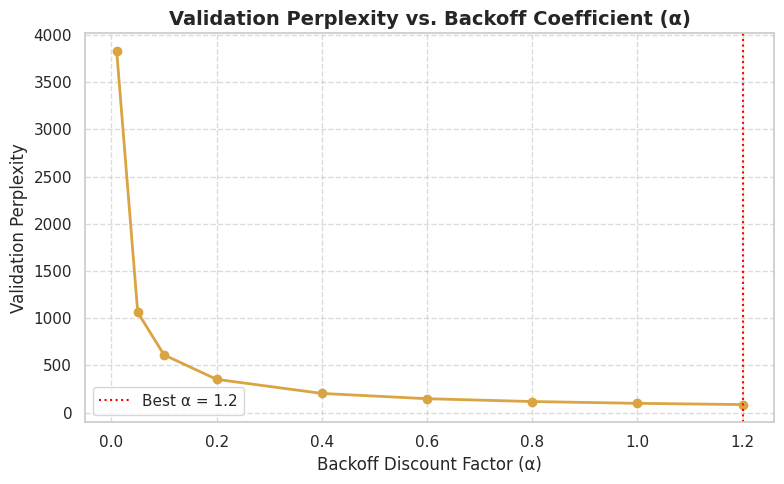

In [ ]:
# Plotting Perplexity vs Alpha Curve
plt.figure(figsize=(8, 5))
plt.plot(alphas, backoff_valid_ppls, marker='o', color='#D9A441', linewidth=2, markersize=6)
plt.title('Validation Perplexity vs. Backoff Coefficient (α)', fontsize=14, fontweight='bold')
plt.xlabel('Backoff Discount Factor (α)', fontsize=12)
plt.ylabel('Validation Perplexity', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.axvline(best_alpha, color='red', linestyle=':', label=f'Best α = {best_alpha}')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Test Best Backoff Model
best_backoff_fn = lambda w1, w2, w3: prob_backoff(w1, w2, w3, best_alpha)
backoff_test_ppl = evaluate_trigram_ppl(test_data, best_backoff_fn)
print(f"Best Backoff Alpha: α = {best_alpha}")
print(f"--> Best Backoff Test PPL: {backoff_test_ppl:.2f}")

Best Backoff Alpha: α = 1.2
--> Best Backoff Test PPL: 79.35


<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۴</b>
<br><br>

<b> جدول مقایسه عملکرد نهایی روش‌ها روی داده‌های Validation و Test:</b>
<table style="width:100%; border-collapse: collapse; margin-top: 10px; margin-bottom: 20px; text-align: right;">
  <tr style="border-bottom: 2px solid #D9A441; color: #8A6116;">
    <th style="padding: 8px;">روش هموارسازی / Backoff</th>
    <th style="padding: 8px;">بهترین تنظیمات هایپرپارامتر</th>
    <th style="padding: 8px;">Validation Perplexity</th>
    <th style="padding: 8px;">Test Perplexity</th>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px;"><b>Laplace (Add-1)</b></td>
    <td style="padding: 8px;">بدون هایپرپارامتر</td>
    <td style="padding: 8px; direction: ltr;">3,708.22</td>
    <td style="padding: 8px; direction: ltr;">3,748.66</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px;"><b>Linear Interpolation</b></td>
    <td style="padding: 8px; direction: ltr;">λ1=0.33, λ2=0.33, λ3=0.34</td>
    <td style="padding: 8px; direction: ltr;">206.87</td>
    <td style="padding: 8px; direction: ltr; font-weight: bold; color: #8A6116;">192.14</td>
  </tr>
  <tr style="border-bottom: 2px solid #D9A441;">
    <td style="padding: 8px;"><b>Stupid Backoff</b></td>
    <td style="padding: 8px; direction: ltr;">α = 1.2</td>
    <td style="padding: 8px; direction: ltr;">76.80</td>
    <td style="padding: 8px; direction: ltr; font-weight: bold; color: #8A6116;">79.35</td>
  </tr>
</table>

<b> جدول ارزیابی ترکیب‌های مختلف λ در Linear Interpolation روی Validation:</b>
<table style="width:100%; border-collapse: collapse; margin-top: 10px; margin-bottom: 20px; text-align: right;">
  <tr style="border-bottom: 2px solid #D9A441; color: #8A6116;">
    <th style="padding: 8px;">λ1 (Unigram)</th>
    <th style="padding: 8px;">λ2 (Bigram)</th>
    <th style="padding: 8px;">λ3 (Trigram)</th>
    <th style="padding: 8px;">Validation Perplexity</th>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px; direction: ltr;">0.05</td>
    <td style="padding: 8px; direction: ltr;">0.15</td>
    <td style="padding: 8px; direction: ltr;">0.80</td>
    <td style="padding: 8px; direction: ltr;">368.21</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px; direction: ltr;">0.10</td>
    <td style="padding: 8px; direction: ltr;">0.30</td>
    <td style="padding: 8px; direction: ltr;">0.60</td>
    <td style="padding: 8px; direction: ltr;">259.16</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px; direction: ltr;">0.15</td>
    <td style="padding: 8px; direction: ltr;">0.35</td>
    <td style="padding: 8px; direction: ltr;">0.50</td>
    <td style="padding: 8px; direction: ltr;">230.30</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px; direction: ltr;">0.20</td>
    <td style="padding: 8px; direction: ltr;">0.40</td>
    <td style="padding: 8px; direction: ltr;">0.40</td>
    <td style="padding: 8px; direction: ltr;">213.49</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3); background-color: rgba(217, 164, 65, 0.15);">
    <td style="padding: 8px; direction: ltr; font-weight: bold;">0.33</td>
    <td style="padding: 8px; direction: ltr; font-weight: bold;">0.33</td>
    <td style="padding: 8px; direction: ltr; font-weight: bold;">0.34</td>
    <td style="padding: 8px; direction: ltr; font-weight: bold;">206.87 (Best)</td>
  </tr>
  <tr style="border-bottom: 2px solid #D9A441;">
    <td style="padding: 8px; direction: ltr;">0.01</td>
    <td style="padding: 8px; direction: ltr;">0.09</td>
    <td style="padding: 8px; direction: ltr;">0.90</td>
    <td style="padding: 8px; direction: ltr;">632.10</td>
  </tr>
</table>

---

<b>
تحلیل رفتار ضریب α در روش Stupid Backoff (نمودار Perplexity-α)
</b>

با توجه به نموداری که در بالا مشاهده می شود، زمانی که آلفا کوچک باشد، جریمه backoff به مرتبه های پایین تر خیلی بیشتر می شود پس اگر یک trigram در داده های آموزشی نباشد، مدل پس از عقب نشینی احتمال بسیار پایینی به آن اختصاص می دهد. این باعث می شود که مدل در مواجهه با داده های validation عملکرد بدی داشته باشد و perplexity بالا باشد.

با افزایش مقدار آلفا این جریمه backoff متعادل تر می شود و مدل زمانی که اطلاعات کافی در مرتبه های بالاتر ندارد، از اطلاعات مراتب پایین تر بهتر استفاده می کند. در این حالت، perplexity کاهش می یابد.

---

<b>
دلیل ضعف هموارسازی Laplace در واژگان بزرگ
</b>

همانطور که می دانیم، در این روش به مخرج کسر احتمال، اندازه vocabulary اضافه می شود. هرچه این مقدار بزرگتر باشد، مقدار بیشتری به مخرج کسر اضافه می شود و در نتیجه احتمال کاهش می یابد. همچنین این روش برای تمام کلمات واژگان، حتی آنهایی که ارتباط چندانی با کانتکست فعلی ندارند مقداری احتمال درنظر می گیرد که این کار باعث می شود بخشی از احتمالات بصورت یکنواخت بین کلمات محتلف توزیع شود و احتمال کلماتی که واقعا محتمل هستند کاهش پیدا کند.

از روی مقدار perplexity (نسبت به دو روش دیگر) هم مشخص استکه مدل لاپلاس نمی تواند بین کلمات مرتبط و غیرمرتبط با کانتکست، تمایز خوبی ایجاد کند و در داده هایی با واژگان بزرگ و پراکندگی بالا عملکرد خوبی نخواهد داشت.

البته باید اضافه کنم که در این روش، خروجی ها احتمال واقعی نیستند و صرفا یک امتیاز هستند، اما فرمول perplexity بااین پیش فرض کار می کند که مقادیر، احتمال واقعی بین 0 و 1 هستند. هرچه آلفا را بزرکتر از 1 کنیم، امتیاز توالی های backoff بشکلی مصنوعی افزایش می یابند و perplexity بطور نادقیق و اصطلاحا کاذبی کاهش می یابد.

</div>

<div dir="rtl" align="right">

### ۲.۵ جمع‌بندی نتایج و مصورسازی (۱۰ نمره)

**صورت مسئله**

پس از ارزیابی همه‌ی مدل‌ها، نتایج باید در قالب یک جدول جمع‌بندی شده و به‌صورت نمودار مقایسه شوند تا تفاوت عملکرد روش‌های مختلف به‌وضوح مشخص شود.

**آنچه باید انجام دهید**

- جدولی از perplexity همه‌ی مدل‌ها روی test تهیه کنید.
- نمودار میله‌ای (bar plot) perplexity مدل‌ها را رسم کنید (با مقیاس لگاریتمی برای نمایش بهتر).
- شکاف بین perplexity روی valid و test را تحلیل کنید و در مورد overfitting اظهارنظر کنید.
- بهترین مدل را بر اساس کم‌ترین perplexity مشخص کنید.
- در پاسخ تشریحی، نتایج را تحلیل کنید و توضیح دهید چرا هموارسازی و backoff باعث بهبود چشمگیر می‌شوند.

</div>

--- Language Models Perplexity Summary ---
               Model  Valid Perplexity  Test Perplexity
           MLE (N=1)            617.99           576.98
           MLE (N=2)           2969.86          2267.39
           MLE (N=3)        1883300.70       1674916.80
           MLE (N=4)    10000000000.00     197956898.96
       Laplace (N=3)           3708.22          3748.66
 Interpolation (N=3)            206.87           192.14
Stupid Backoff (N=3)             84.17            79.35




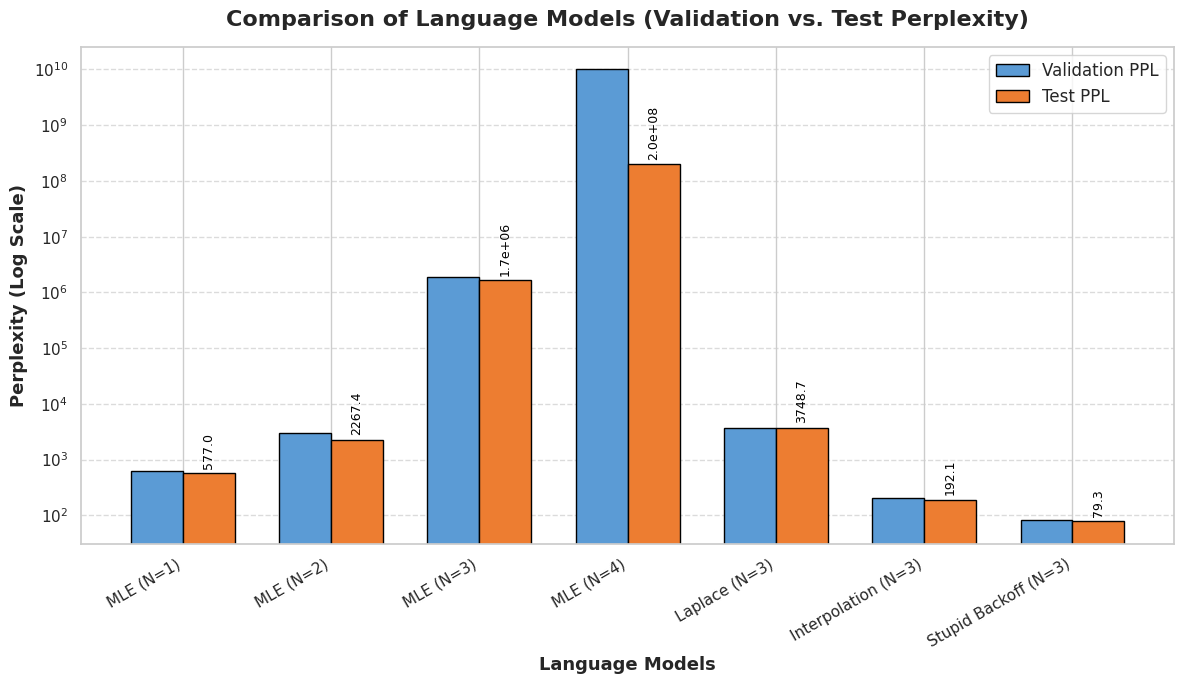


BEST MODEL: Stupid Backoff (N=3) with Test Perplexity = 79.35


In [ ]:
# ==============================================================
# Part 2.5 — Results Summary and Visualization
# ==============================================================
# Compile all results into a Dictionary
results_data = {
    'Model': [
        'MLE (N=1)', 'MLE (N=2)', 'MLE (N=3)', 'MLE (N=4)',
        'Laplace (N=3)', 'Interpolation (N=3)', 'Stupid Backoff (N=3)'
    ],
    'Valid Perplexity': [
        model_1.perplexity(valid_data),
        model_2.perplexity(valid_data),
        model_3.perplexity(valid_data),
        NGramModel(n=4, vocab=vocab).train(train_data) or NGramModel(n=4, vocab=vocab).perplexity(valid_data), # Calculate N=4 valid
        laplace_valid_ppl,
        evaluate_trigram_ppl(valid_data, best_interp_fn),
        evaluate_trigram_ppl(valid_data, best_backoff_fn)
    ],
    'Test Perplexity': [
        mle_perplexities[1],
        mle_perplexities[2],
        mle_perplexities[3],
        mle_perplexities[4],
        laplace_test_ppl,
        interp_test_ppl,
        backoff_test_ppl
    ]
}

# Create DataFrame
summary_df = pd.DataFrame(results_data)

# Display the Summary Table
print("--- Language Models Perplexity Summary ---")
print(summary_df.to_string(index=False, float_format="%.2f"))
print("\n")

# Create the Bar Plot (Log Scale)
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# Set bar width and positions
bar_width = 0.35
x = np.arange(len(summary_df['Model']))

# Plot bars
plt.bar(x - bar_width/2, summary_df['Valid Perplexity'], bar_width, label='Validation PPL', color='#5B9BD5', edgecolor='black')
plt.bar(x + bar_width/2, summary_df['Test Perplexity'], bar_width, label='Test PPL', color='#ED7D31', edgecolor='black')

# Formatting the plot
plt.title('Comparison of Language Models (Validation vs. Test Perplexity)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Language Models', fontsize=13, fontweight='bold')
plt.ylabel('Perplexity (Log Scale)', fontsize=13, fontweight='bold')
plt.xticks(x, summary_df['Model'], rotation=30, ha='right', fontsize=11)
plt.yscale('log') # Crucial for displaying millions vs tens!
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.legend(fontsize=12)

for i, val in enumerate(summary_df['Test Perplexity']):
    if val > 10000:
        label = f"{val:.1e}"
    else:
        label = f"{val:.1f}"
    plt.text(i + bar_width/2, val * 1.2, label, ha='center', va='bottom', fontsize=9, rotation=90, color='black')

plt.tight_layout()
plt.show()

# Identify the Best Model
best_model_idx = summary_df['Test Perplexity'].idxmin()
best_model_name = summary_df.loc[best_model_idx, 'Model']
best_model_ppl = summary_df.loc[best_model_idx, 'Test Perplexity']

print(f"\nBEST MODEL: {best_model_name} with Test Perplexity = {best_model_ppl:.2f}")

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۵</b>
<br><br>

<b>جدول جمع‌بندی Perplexity تمام مدل‌های زبانی:</b>
<table style="width:100%; border-collapse: collapse; margin-top: 10px; margin-bottom: 20px; text-align: right;">
  <tr style="border-bottom: 2px solid #D9A441; color: #8A6116;">
    <th style="padding: 8px;">مدل زبانی (Model)</th>
    <th style="padding: 8px;">Validation Perplexity</th>
    <th style="padding: 8px;">Test Perplexity</th>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px; direction: ltr; text-align: right;">MLE (N=1)</td>
    <td style="padding: 8px; direction: ltr;">617.99</td>
    <td style="padding: 8px; direction: ltr;">576.98</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px; direction: ltr; text-align: right;">MLE (N=2)</td>
    <td style="padding: 8px; direction: ltr;">2,969.86</td>
    <td style="padding: 8px; direction: ltr;">2,267.39</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px; direction: ltr; text-align: right;">MLE (N=3)</td>
    <td style="padding: 8px; direction: ltr;">1,883,300.70</td>
    <td style="padding: 8px; direction: ltr;">1,674,916.80</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px; direction: ltr; text-align: right;">MLE (N=4)</td>
    <td style="padding: 8px; direction: ltr;">10,000,000,000.00</td>
    <td style="padding: 8px; direction: ltr;">197,956,898.96</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px; direction: ltr; text-align: right;">Laplace (N=3)</td>
    <td style="padding: 8px; direction: ltr;">3,708.22</td>
    <td style="padding: 8px; direction: ltr;">3,748.66</td>
  </tr>
  <tr style="border-bottom: 1px solid rgba(217, 164, 65, 0.3);">
    <td style="padding: 8px; direction: ltr; text-align: right;">Interpolation (N=3)</td>
    <td style="padding: 8px; direction: ltr;">206.87</td>
    <td style="padding: 8px; direction: ltr;">192.14</td>
  </tr>
  <tr style="border-bottom: 2px solid #D9A441; background-color: rgba(217, 164, 65, 0.15);">
    <td style="padding: 8px; direction: ltr; text-align: right; font-weight: bold;">Stupid Backoff (N=3)</td>
    <td style="padding: 8px; direction: ltr; font-weight: bold;">84.17</td>
    <td style="padding: 8px; direction: ltr; font-weight: bold; color: #8A6116;">79.35 (Best)</td>
  </tr>
</table>

---

<b>
تحلیل اختلاف Perplexity در Validation و Test و بررسی Overfitting
</b>

همانطور که می دانیم علاوه بر perplexity باد ببینیم مدل روی داده های validation و test چه رفتاری دارد.

در نتایج این آزمایش ، در مدل های پایه MLE، مقدار perplexity هم در validation و هم در test بسیار بالا است، اما این موضوع بیشتر به دلیل مشکل Data Sparsity است و در واقع کمبود داده های آموزشی برای ترکیب های مختلف کلمات، باعث شده تا مدل نتواند به خوبی توالی های جدید را پیش بینی کند.

اما هنگامیکه روش های smoothing را اضافه کردیم دیدیم که perplexity کاهش چشمگیری داشت و با استفاده از داده های موجود در جدول بخش قبل، اختلاف بین Validation و Test بسیار کمتر شده است که این نشان می دهد عملکرد مدل در مواحهه با داده های جدید، تقریبا حفظ شده است؛ پس با توجه به توضیحات، نشانه ای از Overfitting شدید در این مدل ها مشاهده نمی شود.

---

<b>
انتخاب بهترین مدل
</b>

معیار ما در اینجا برای انتخاب بهترین مدل، perplexity است. هرچه کمتر باشد نشان می دهد مدل نسبت به توالی های واقعی زبان، سردرگمی کمتری نشان می دهد.

طبق جدول بالا، بهترین مدل ما مدل Stupid Backoff می باشد. (این نتیجه مربوط به همین داده ها است و لزوما به معنی بهتر بودن این مدل در همه شرایط نیست.)

---

<b>
دلیل بهبود عملکرد با استفاده از روش‌های هموارسازی و Backoff
</b>

با توجه به تعریف روش MLE، میدانیم این روش به تعداد دفعات مشاهده توالی های مختلف در داده های آموزشی است. پس اگر توالی دیده نشده باشد،احتمال آن صفر می شود و این باعث می شود perplexity به سمت بی نهایت حرکت کند.

اما در روش های Stupid Backoff و Linear Interpolation سعی شده این مشکل برطرف شود. در واقع از اطلاعات N-gram های کوتاه تر استفاده میکند.Backoff در صورت دیده نشدن سه تایی، به سراغ دوتایی و یکی خواهد رفت و Linear Interpolation اطلاعات این سه مرتبه را بطور همزمان با هم ترکیب می کند.

در مجموع این روش ها با کاهش اثر پراکندگی داده ها و استفاده از اطلاعات توالی های کوتاه تر، نسبت به MLE عملکرد بهتری در پیش بینی توای هایی که دیده نشده خواهند داشت.

</div>

<div dir="rtl" align="right">

### ۲.۶ تولید متن از بهترین مدل (۵ نمره)

**صورت مسئله**

یکی از کاربردهای مدل‌های زبانی، تولید متن است. در این زیربخش، از بهترین مدل (کم‌ترین perplexity روی test) برای تولید چند جمله‌ی نمونه استفاده می‌کنیم. تولید به‌صورت تدریجی و با نمونه‌گیری وزن‌دار از توزیع احتمال انجام می‌شود.

**آنچه باید انجام دهید**

- بهترین مدل را بر اساس perplexity مشخص کنید.
- یک تابع تولید متن پیاده‌سازی کنید که از توزیع احتمال مدل، توکن بعدی را نمونه‌گیری کند.
- حداقل ۵ جمله با سه دمای مختلف (مثلاً T=0.5، ۱، ۱.۵) تولید کنید و تفاوت کیفیت را تحلیل کنید و تاثیر دما در تولید متن را بیان کنید.

</div>

In [ ]:
# ==============================================================
# Part 2.6 — Text Generation from the Best Model
# ==============================================================
best_alpha = 1.2
vocab_list = list(vocab)

def generate_text(max_len=30, temperature=1.0):
    """
    Generates text by sampling from the probability distribution of the best model.
    """
    sentence = ['<s>']

    for _ in range(max_len):
        # Get the context: last two words for a Trigram model
        if len(sentence) >= 2:
            w1, w2 = sentence[-2], sentence[-1]
        else:
            w1, w2 = '<s>', sentence[-1] # Fallback if we only have 1 word

        # Calculate backoff scores for ALL words in the vocabulary given the context
        scores = []
        for w3 in vocab_list:
            score = prob_backoff(w1, w2, w3, best_alpha)
            scores.append(score)

        scores = np.array(scores)

        # Prevent zero scores to avoid math errors during temperature scaling
        scores = np.clip(scores, 1e-10, None)

        # Apply Temperature scaling
        if temperature == 0.0:
            # Greedy decoding (argmax) if T is exactly 0
            next_word_idx = np.argmax(scores)
        else:
            scaled_scores = np.power(scores, 1.0 / temperature)
            probabilities = scaled_scores / np.sum(scaled_scores)

            # Weighted sampling from the distribution
            next_word_idx = np.random.choice(len(vocab_list), p=probabilities)

        next_word = vocab_list[next_word_idx]
        sentence.append(next_word)

        # Stop generation if the end-of-sentence token is produced
        if next_word == '</s>':
            break

    # Return the generated sentence (excluding the boundary tokens for clean output)
    return " ".join([w for w in sentence if w not in ['<s>', '</s>']])

# 2. Generate 5 sentences for 3 different temperatures (T=0.5, T=1.0, T=1.5)
temperatures = [0.5, 1.0, 1.5]

for T in temperatures:
    print(f"\n--- 5 sentences with Temperature T={T} ---")
    for i in range(5):
        gen_sent = generate_text(max_len=20, temperature=T)
        print(f"{i+1}. {gen_sent}")


--- 5 sentences with Temperature T=0.5 ---
1. the company 's the to <unk> oil by their a <unk> in a <unk> of <unk> <unk>
2. the mr. of the <unk> of the <unk> <unk> <unk> <unk> <unk> and <unk>
3. it 's a the <unk> the the the <unk> of the the to $ N
4. the and other terms
5. the company 's <unk> <unk> <unk>

--- 5 sentences with Temperature T=1.0 ---
1. the airports in network of <unk> the smaller industrial units
2. david dinkins 's demise capable mr. in the appeared million or part suspended chinese i coke chief cost international out
3. one agent operating an increase is part of on patients we had lots of art by <unk> n't cheating says
4. any obligation to the launching
5. reflect it is have is that renewing a defense N

--- 5 sentences with Temperature T=1.5 ---
1. reporting more father profitably products and when foreigners bogart west precious co an individual ginnie international organization life bankamerica
2. courts a disrupt and guard bureau foothills second damages schools

<div dir="rtl" style="box-sizing:border-box; max-width:100%; background-color:#FFF8E7; color:#2B2317; border-right:4px solid #D9A441; border-radius:6px; padding:16px 20px; margin:6px 0; line-height:1.9; text-align:right; overflow-wrap:break-word;">
<b style="color:#8A6116;">پاسخ تشریحی ۲.۶</b>
<br><br>

<b>
تحلیل تأثیر دما بر کیفیت و تنوع متن
</b>

دما میزان تصادفی بودن انتخاب کلمات توسط مدل را کنترل می کند و در واقع با تغییر آن، میتوان بین تنوع (یا حتی خلاقیت) و انسجام متن مصالحه ایجاد کرد.

همانطور که در خروجی سلول آخر (جملات تولید شده) مشخص است، هنگامیکه دما را کمتر از 1 قرار داده ایم، به نوعی مدل را بیش از حد محافظه کار کرده ایم و مدل بیشتر یه توکن هایی که در داده های آموزشی تکرار زیادی داشته اند اجازه حضور می دهد؛ مشاهده می شود که جملات این بخش، بسیار از حروف اضافه و توکن unk تشکیل شده اند.

اما هنگامیکه دما را برابر 1 قرار می دهیم، مدل دقیقا از همان دانشی که فراگرفته استفاده میکند و نمونه گیری می کند. میبینیم که تیزی مدل نسبت به حالتی که دما کمتر از 1 بود کمتر شده و همچنین حملات تولیدی روان تر و طبیعی تر شده اند.مثلا در جمله اول عبارت "the airport in network" نشان می دهد که ترکیب واژگان و حروف اضافه بطور طبیعی تولید شده اند پس مدل درست یادگرفته است؛ علاوه بر آن از آنجا که مدل برای تصمیم گیری به دو توکن قبلی نگاه می کند، شاید جملات از نظر معنایی تمرکز مشخصی ندارند، اما یادگیری در همان  پنجره کوتاه انجام شده، چراکه ترکیب واژگان و حروف ربط به درستی مشاهده می شوند.

اما هنگامیکه دما را بزرگتر از 1 قرار می دهیم، توزیع احتمالی که مدل یادگرفته هموار تر می شود و این باعث می شود کلماتی که کمتر دیده شده اند و احتمال رخدادشان کم است، شانسان برای تولید بیشتر شود. به همین دلیل در خروجی هم میتوان دید که نسبت به دمای 1 کلمات عجیب غریب و بیربط نسبتا زیادی تولید شده اند و تمرکز معنایی جمله کمتر شده است.

</div>

<div dir="rtl" align="right">

## منابع و ابزارهای کمکی

هر منبعی که در انجام این تکلیف از آن استفاده کرده‌اید (مقاله، مستندات کتابخانه، مخزن کد، پست وبلاگ) و نیز — مطابق سیاست درس — هرگونه استفاده از ابزارهای هوش مصنوعی مولد را در جدول زیر ذکر کنید. اعلام نکردن منابع و ابزارهای استفاده‌شده، مصداق نقض صداقت علمی است.

| ردیف | منبع یا ابزار | محل استفاده (شماره‌ی بخش) | نحوه‌ی استفاده |
|---|---|---|---|
| ۱ | Gemini(https://share.gemini.google/i78pi5rPg3Sh) | بخش های مختلف تمرین | سعی کردم بعنوان یک دستیار در درک بهتر مطالب و خروجی ها استفاده کنم، همچنین در برخی موارد پایه کد ها را میگرفتم و پس از بررسی و تسلط کافی به کدهای تولید شده، از آنها استفاده کردم.  |

</div>

<div dir="rtl" align="right">

## چک‌لیست پیش از ارسال

- [ ] جدول مشخصات دانشجو تکمیل شده است.
- [ ] همه‌ی سلول‌های دارای نشانه‌ی `WRITE YOUR CODE HERE` تکمیل شده‌اند.
- [ ] همه‌ی سلول‌های پاسخ تشریحی تکمیل شده و هیچ `{{پاسخ_خود_را_اینجا_بنویسید}}` باقی نمانده است.
- [ ] بخش جمع‌بندی و جدول منابع و ابزارهای کمکی تکمیل شده است.
- [ ] نوت‌بوک با `Restart & Run All` بدون خطا اجرا شده و خروجی همه‌ی سلول‌ها در فایل ذخیره شده است.
- [ ] نام فایل مطابق الگوی `NLP_CA1_{LASTNAME}_{STUDENTID}.ipynb` است.

</div>

---

<div dir="rtl" align="right">

## قوانین تحویل و صداقت علمی

### ۱. مهلت و نحوه‌ی ارسال

- مهلت تحویل: ۹ / ۸ / ۱۴۰۵
- مهلت تحویل با تأخیر: ۱۶ / ۸ / ۱۴۰۵ — با اعمال جریمه‌ی ۱۰٪ به ازای هر روز تأخیر
- فایل ارسالی باید با این قالب نام‌گذاری شود: `NLP_CA1_{LASTNAME}_{STUDENTID}.ipynb`
- تنها فایل نوت‌بوک اجراشده پذیرفته می‌شود. به تکالیفی که به‌صورت کاغذی تحویل داده شوند یا به‌صورت تصویر در سامانه بارگذاری شوند، ترتیب اثری داده نخواهد شد.

### ۲. صداقت علمی

- نوت‌بوک تعداد مشخصی از دانشجویان که به‌صورت تصادفی انتخاب می‌شوند بررسی خواهد شد. این بررسی‌ها اطمینان حاصل می‌کنند که کدی که نوشته‌اید واقعاً پاسخ‌های موجود در نوت‌بوک شما را تولید می‌کند. ارائه‌ی پاسخ‌های درست بدون کدی که آن پاسخ‌ها را تولید کرده باشد، موردی جدی از عدم صداقت علمی محسوب می‌شود.
- بررسی‌های خودکار برای تشخیص سرقت علمی روی نوت‌بوک‌ها انجام می‌شود. کپی کردن کد از دیگران نیز موردی جدی از عدم صداقت علمی است.
- این تکلیف باید به‌صورت تک‌نفره انجام شود و پاسخ‌ها باید نتیجه‌ی فعالیت شخص نویسنده باشد؛ هم‌فکری و نوشتن مشترک تمرین نیز مجاز نیست. در صورت مشاهده‌ی تشابه، نمره‌ی تمرین برای همه‌ی افراد مشارکت‌کننده صفر و موضوع به استاد گزارش می‌شود.

### ۳. کد و گزارش

- همه‌ی کدهای پیوست گزارش باید قابلیت اجرای مجدد داشته باشند. اگر اجرای دوباره به تنظیمات خاصی نیاز دارد، آن تنظیمات را در گزارش ذکر کنید.
- همه‌ی کدها باید توسط خودتان اجرا شده و نتایج اجرا در فایل ارسالی قابل مشاهده باشد. به کدهایی که نتیجه‌ی اجرای آن‌ها در فایل ارسالی مشخص نباشد نمره‌ای تعلق نمی‌گیرد.
- خوانایی گزارش و دقت تحلیل‌ها در نمره‌دهی اهمیت ویژه دارد.

### ۴. پرسش و پاسخ

- پرسش‌های خود درباره‌ی این تکلیف را در گروه بله یا تلگرام یا از طریق ایمیل azerila.farshi@gmail.com مطرح کنید و در ایمیل‌ها حتماً چیف تی‌ای درس (msabour.official@gmail.com) را cc کنید.
